## <font color=#0099CC>mIAx - Taller Renta Fija - ANÁLISIS CARTERA DE RENTA FIJA</font>

En esta práctica, desarrollaremos un análisis exahustivo de un universo de Renta Fija, en concreto, de bonos corporativos. Además, construiremos y analizaremos varias carteras. 

Para ello, contaremos con la siguiente información almacenada en la carpeta *data*:
- **Universo de bonos**, con sus características esenciales (fichero *universo.csv*)
- **Histórico de precios** de cierre del universo de bonos anterior (fichero *precios_historicos_universo.csv*)
- **Curva de tipos de interés €STR** (fichero *curvaESTR.csv*)
- **Histórico de precios de otros índices** que nos serán de utilidad (fichero *precios_historicos_varios.csv*):
    - Índices de crédito: ITRAXX Main y ITRAXX XOVER. Serán útiles para la cobertura del riesgo de crédito.
    - Futuros sobre el *Schatz* (DU1), *BOBL* (OE1) y *BUND* (RX1). Serán útiles para la cobertura de los tipos de interés.
    - Índice de crédito *RECMTREU*, que valdría como benchmark de las carteras que construyamos.

No necesariamente se usará toda toda la información.

📣 <font color=#CC6600>**¡NORMAS!**</font>

La práctica se puede hacer en grupos de hasta **3 personas** y deberá entregarse antes del **26 de noviembre**. 

**ENTREGABLES**: 
* **Carpeta .zip** con el nombre del capitán del grupo.
* La carpeta debe mantener la estructura original.
* Los ficheros **funciones_aux.py** y **analisis_cartera.ipynb** deben completarse según se considere. 
* Deberán ser ejecutables y **enviarse ya debidamente ejecutados** y con los **resultados guardados**.
* Todo el **código debe estar comentado y razonado.**
* Las **celdas de texto deben responder explícitamente a las preguntas realizadas.**
* En la subcarpeta **"results" deberán estar los ficheros .csv** que se piden en los diferentes apartados.

Cada grupo expondrá una parte de los ejercicios en la clase del día 26, donde la resolveremos juntos a modo de taller. Esta exposición contará hasta **1 punto** de la nota final.
Cada apartado de esta práctica también contará hasta **1 punto** de la nota final.

Además, se valorará positivamente para la práctica la participación en las clases.

📣 <font color=#CC6600>**¡IMPORTANTE!**</font>

Todo el código implementado debe estar debidamente comentado e incluir conclusiones de los resultados obtenidos para optar a la máxima puntuación. Asimismo, se debe responder a las preguntas planteadas.

Las propuestas de mejora o posibles trabajos futuros se valorarán positivamente también.

Usa las fuentes de información que consideres necesarias para apoyar tus respuestas.

### <font color=#336699>Librerías</font>

In [1]:
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Estilo de los gráficos
plt.style.use('dark_background')

# Fecha de análisis: todas las valoraciones del trabajo se hacen a este día
fecha_analisis = pd.to_datetime('2026-10-01')

# El notebook está en src/ y los datos en ../data/
RUTA_DATOS = '../data/'
RUTA_RESULTS = '../results/'


In [2]:
# Recarga automáticamente funciones_aux.py cada vez que lo modifiquemos
%load_ext autoreload
%autoreload 2

# Importamos nuestras funciones auxiliares con el alias 'fa'
import funciones_aux as fa

### <font color=#336699>1. Datos</font>

**Análisis de datos.** En esta sección, haremos un análisis de la información que tenemos de cada bono y lo que significa. Asimismo, haremos los tratamientos y limpieza que necesitemos para luego poder usarlos.

Haz un primer análisis visual de la información que tenemos del universo de bono.
Entre otras, plantéate cuestiones como:
- ¿Divisas?
- ¿Tipo de bonos? ¿Fijo/Flotante? ¿Prelación? ¿Opcionalidad? ¿Hay bonos perpetuos?
- ¿Sectores? ¿Emisores? Si invirtéramos en todos los bonos, ¿dirías a priori que la cartera está diversificada?
- ¿Ratings? (Riesgo de crédito)
- ¿Otros datos cuantitativos?
    - Riesgo de liquidez - Horquillas y nominal vivo
- ¿Hay *gaps* en la información que vamos a tener que tratar?

**Guarda en "results" dos ficheros .csv:
1. "control_calidad_universo.csv" generado con la infomación del fichero universo.csv y que contenga las siguientes columnas para cada característica de los bonos:**
- número de observaciones
- número de datos *missing*
- número de valores únicos
- mínimo y máximo si aplica

2. "control_calidad_precios.csv" generado con la infomación del fichero precios_historicos_universo.csv y que para cada bono contenga las siguientes columnas:
- número de observaciones
- número de datos *missing*
- mínimo y máximo
- fecha inicio y fecha fin de cotización

Saca conclusiones de estas tablas de control. Identifica al menos 2 posibles problemas de calidad en estos dos ficheros que puedan afectar a los cálculos posteriores. Para cada uno, indica:
- problema
- tratamiento propuesto
- número de bonos afectados
- consecuencia de no tratarlo

In [3]:
# Cargamos el universo de bonos
universo = pd.read_csv(
    RUTA_DATOS + 'universo.csv',
    sep=';',                    # el fichero usa ; como separador
    encoding='utf-8-sig',       # elimina el carácter BOM invisible del inicio del fichero
    na_values=['#N/A N/A']      # marcador de "sin dato" de Bloomberg -> NaN
)

# Convertimos las columnas de fecha de texto (dd/mm/aaaa) a fechas reales
cols_fecha = ['Maturity', 'Next Call Date', 'First Coupon Date',
              'Penultimate Coupon Date', 'Issue date']
for col in cols_fecha:
    universo[col] = pd.to_datetime(universo[col], format='%d/%m/%Y')

# Usamos el ISIN como índice: es el identificador único de cada bono
universo = universo.set_index('ISIN')

# Primer vistazo: tipos de cada columna y valores no nulos
universo.info()
universo.head()

<class 'pandas.DataFrame'>
Index: 2165 entries, XS0161488498 to XS2694995163
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Description              2165 non-null   str           
 1   Ccy                      2165 non-null   str           
 2   Price                    2165 non-null   float64       
 3   Issuer                   2165 non-null   str           
 4   Industry Sector          2165 non-null   str           
 5   Maturity                 2147 non-null   datetime64[us]
 6   Coupon                   2165 non-null   float64       
 7   Rating                   2162 non-null   str           
 8   PD 1YR                   2142 non-null   float64       
 9   Outstanding Amount       2165 non-null   int64         
 10  Callable                 2165 non-null   str           
 11  Next Call Date           1582 non-null   datetime64[us]
 12  Seniority                2165 n

,Description,Ccy,Price,Issuer,Industry Sector,Maturity,Coupon,Rating,PD 1YR,Outstanding Amount,Callable,Next Call Date,Seniority,Coupon Frequency,Coupon Type,First Coupon Date,Penultimate Coupon Date,Issue date,Bid Price,Ask Price
ISIN,,,,,,,,,,,,,,,,,,,,
XS0161488498,DT 7 ½ 01/24/33,EUR,117.8740,DEUTSCHE TELEKOM INT FIN,Communications,2033-01-24,7.500,BBB+,0.021966,500000000,N,NaT,Sr Unsecured,1,FIXED,2004-01-24,2032-01-24,2003-01-24,117.6614,118.0866
FR0000471930,ORAFP 8 ⅛ 01/28/33,EUR,121.4000,ORANGE SA,Communications,2033-01-28,8.125,BBB+,0.000021,1500000000,N,NaT,Sr Unsecured,1,FIXED,2004-01-28,2032-01-28,2003-01-28,121.1417,121.6583
XS0162513211,EOANGR 5 ¾ 02/14/33,EUR,108.3925,E.ON INTL FINANCE BV,Utilities,2033-02-14,5.750,BBB+,0.000101,600000000,N,NaT,Sr Unsecured,1,FIXED,2004-02-14,2032-02-14,2003-02-14,108.1680,108.6170
XS0162869076,TELEFO 5 ⅞ 02/14/33,EUR,108.1155,TELEFONICA EUROPE BV,Communications,2033-02-14,5.875,BBB-,0.000125,500000000,N,NaT,Sr Unsecured,1,FIXED,2004-02-14,2032-02-14,2003-02-14,107.8141,108.4169
FR0010014845,PEUGOT 6 09/19/33,EUR,102.0467,PSA TRESORERIE GIE,"Consumer, Cyclical",2033-09-19,6.000,BBB,0.024240,600000000,N,NaT,Sr Unsecured,1,FIXED,2004-09-19,2032-09-19,2003-09-19,101.6177,102.4757


In [4]:
import os

# Control de calidad del universo con las columnas ORIGINALES del fichero
# (leemos solo la cabecera del CSV, nrows=0, para no depender de las columnas
#  que añadimos después en el notebook)
cols_fichero = pd.read_csv(RUTA_DATOS + 'universo.csv', sep=';',
                           encoding='utf-8-sig', nrows=0).columns
cc_universo = fa.control_calidad_universo(universo.reset_index()[cols_fichero])

os.makedirs(RUTA_RESULTS, exist_ok=True)
cc_universo.to_csv(RUTA_RESULTS + 'control_calidad_universo.csv', sep=';')
cc_universo

,NumObservaciones,NumMissing,NumValoresUnicos,Minimo,Maximo
Caracteristica,,,,,
ISIN,2165,0,2165,NaN,NaN
Description,2165,0,2163,NaN,NaN
Ccy,2165,0,1,NaN,NaN
Price,2165,0,2164,43.1028,121.4
Issuer,2165,0,605,NaN,NaN
Industry Sector,2165,0,9,NaN,NaN
Maturity,2147,18,1438,2026-12-04 00:00:00,2083-06-30 00:00:00
Coupon,2165,0,314,0.0,9.875
Rating,2162,3,12,NaN,NaN


Tabla de control de calidad del universo: **una fila por cada una de las 21 columnas originales** del fichero (ISIN y 20 características), con nº de observaciones, *missing*, valores únicos y mínimo/máximo. Se genera antes de añadir columnas propias y se guarda en `results/control_calidad_universo.csv`. Las conclusiones del control de calidad están en el apartado *Precios bonos universo*.

#### <font color=#808080>Divisas</font>

In [5]:
# Número de bonos por divisa
universo['Ccy'].value_counts()

Ccy
EUR    2165
Name: count, dtype: int64

Los 2.165 bonos están en **EUR**. Esto tiene dos ventajas: no hay **riesgo de divisa** en la cartera, y podemos valorar todos los bonos con **una única curva de descuento en euros (€STR)**, ya que los flujos deben descontarse con tipos de interés de su misma divisa. Si hubiera bonos en otras divisas (p. ej. USD), necesitaríamos su propia curva (p. ej. SOFR) o convertir sus flujos a euros.

#### <font color=#808080>Tipos de bono</font>

In [6]:
# Tipo de cupón: fijo o variable
print(universo['Coupon Type'].value_counts(), '\n')

# Prelación (orden de cobro en caso de impago)
print(universo['Seniority'].value_counts(), '\n')

# Opcionalidad: ¿el emisor puede amortizar anticipadamente?
print(universo['Callable'].value_counts(), '\n')

# Bonos perpetuos = bonos sin fecha de vencimiento
perpetuos = universo[universo['Maturity'].isna()]
print(f'Número de bonos perpetuos: {len(perpetuos)}')
perpetuos[['Description', 'Seniority', 'Coupon Type', 'Next Call Date']]

Coupon Type
FIXED       1835
VARIABLE     330
Name: count, dtype: int64 

Seniority
Sr Unsecured        1614
Sr Non Preferred     182
Sr Preferred         165
Subordinated         147
Jr Subordinated       24
Secured               20
1st lien              13
Name: count, dtype: int64 

Callable
Y    1582
N     583
Name: count, dtype: int64 

Número de bonos perpetuos: 18


,Description,Seniority,Coupon Type,Next Call Date
ISIN,,,,
XS1206541366,VW 3 ½ PERP,Jr Subordinated,VARIABLE,2030-03-20
XS1492580516,SLHNVX 4 ½ PERP,Subordinated,VARIABLE,2027-05-19
XS1629774230,VW 3 ⅞ PERP,Jr Subordinated,VARIABLE,2027-06-14
XS1799939027,VW 4 ⅝ PERP,Jr Subordinated,VARIABLE,2028-06-27
FR0013447877,ORAFP 1 ¾ PERP,Jr Subordinated,VARIABLE,2026-12-19
XS2056730679,IFXGR 3 ⅝ PERP,Jr Subordinated,VARIABLE,2028-01-01
XS2187689380,VW 3 ⅞ PERP,Jr Subordinated,VARIABLE,2029-06-17
XS2195190520,SSELN 3 ⅛ PERP,Jr Subordinated,VARIABLE,2027-04-14
FR00140005L7,ORAFP 1 ¾ PERP,Jr Subordinated,VARIABLE,2028-07-15


- 1.835 bonos (85%) son de **cupón fijo** y 330 **variables**. Los 330 variables son híbridos *fixed-to-floating*: **todos tienen call** y 309 son de **emisores financieros** (bancos y aseguradoras), que los emiten porque computan como capital regulatorio. Si el emisor no ejerce la call, el cupón pasa a flotante.
- Predomina la deuda **Sr Unsecured** (1.614; 75%). Hay 171 bonos subordinados (147 Subordinated + 24 Jr Subordinated) y deuda bancaria Sr Preferred (165) y Sr Non Preferred (182).
- 1.582 bonos (73%) son **callable**, y en 11 la fecha call ya ha pasado.
- Hay **18 perpetuos**, todos subordinados y con cupón variable. Al no tener vencimiento, los valoramos a su **próxima fecha call** (según las instrucciones); el único con la call ya pasada (BNFP 1 PERP) se valora a su próximo cupón (16/12/2026).

#### <font color=#808080>Sectores y emisores</font>

In [7]:
# Número y porcentaje de bonos por sector
sectores = pd.DataFrame({
    'Nº bonos': universo['Industry Sector'].value_counts(),
    '% bonos': (universo['Industry Sector'].value_counts(normalize=True) * 100).round(1)
})
sectores

,Nº bonos,% bonos
Industry Sector,,
Financial,969,44.8
"Consumer, Non-cyclical",391,18.1
Industrial,199,9.2
Communications,168,7.8
"Consumer, Cyclical",165,7.6
Utilities,146,6.7
Basic Materials,65,3.0
Technology,49,2.3
Energy,13,0.6


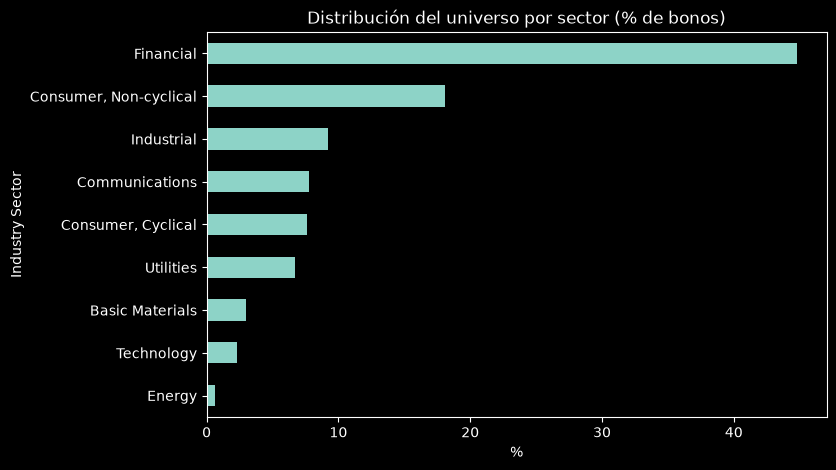

In [8]:
# Gráfico de barras horizontal por sector
sectores['% bonos'].sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('Distribución del universo por sector (% de bonos)')
plt.xlabel('%')
plt.show()

El universo está muy **concentrado en el sector financiero (44,8%)**, seguido de consumo no cíclico (18,1%), industrial (9,2%), comunicaciones (7,8%) y consumo cíclico (7,6%). Energía (0,6%) y tecnología (2,3%) apenas aparecen. Una cartera con todo el universo **no estaría diversificada sectorialmente**: casi la mitad dependería del ciclo bancario y de la regulación financiera, y un shock en el sector (p. ej. una crisis bancaria) afectaría a gran parte de la cartera a la vez.

In [9]:
# Agrupamos por emisor: nº de bonos y nominal vivo total
emisores = universo.groupby('Issuer').agg(
    n_bonos=('Description', 'count'),
    nominal_total=('Outstanding Amount', 'sum')
)

# Peso de cada emisor en una cartera equiponderada (todos los bonos con el mismo peso)
emisores['% cartera_eq'] = (emisores['n_bonos'] / len(universo) * 100).round(2)

print(f'Número de emisores: {len(emisores)}')
emisores.sort_values('n_bonos', ascending=False).head(15)

Número de emisores: 605


,n_bonos,nominal_total,% cartera_eq
Issuer,,,
BANQUE FED CRED MUTUEL,32,32104000000,1.48
BNP PARIBAS,25,30928000000,1.15
BPCE SA,23,21250000000,1.06
ORANGE SA,22,17350000000,1.02
VOLKSWAGEN INTL FIN NV,21,23050000000,0.97
VONOVIA SE,21,14327800000,0.97
SOCIETE GENERALE,21,22250000000,0.97
NESTLE FINANCE INTL LTD,20,13450000000,0.92
CREDIT AGRICOLE SA,19,21500000000,0.88


In [10]:
# Concentración: peso de los 10 emisores con más bonos
top10 = emisores['n_bonos'].nlargest(10).sum() / len(universo) * 100
print(f'Los 10 mayores emisores suponen el {top10:.1f}% del universo')

Los 10 mayores emisores suponen el 10.3% del universo


Hay **605 emisores** (204 de ellos con un solo bono). Los mayores son bancos franceses (BFCM 32 bonos, BNP Paribas 25, BPCE 23, Société Générale 21), además de Orange (22), Volkswagen (21) y Vonovia (21). Los 10 mayores suman el **10,3%** del universo; en una cartera equiponderada, el mayor emisor (BFCM) pesaría un 1,5%.

**¿Está diversificada?** Por número de emisores, sí: ningún emisor tiene un peso relevante por sí solo. Pero, junto con el peso del sector financiero (44,8%), hay una **concentración relevante en banca francesa**, cuyos bonos tienden a moverse juntos ante noticias del sector o del riesgo país de Francia.

ISIN
Internacional (XS)    1542
Francia                390
Alemania               123
Bélgica                 39
España                  17
Suiza                   17
Austria                 16
Dinamarca                8
Portugal                 6
Finlandia                3
Italia                   3
Eslovaquia               1


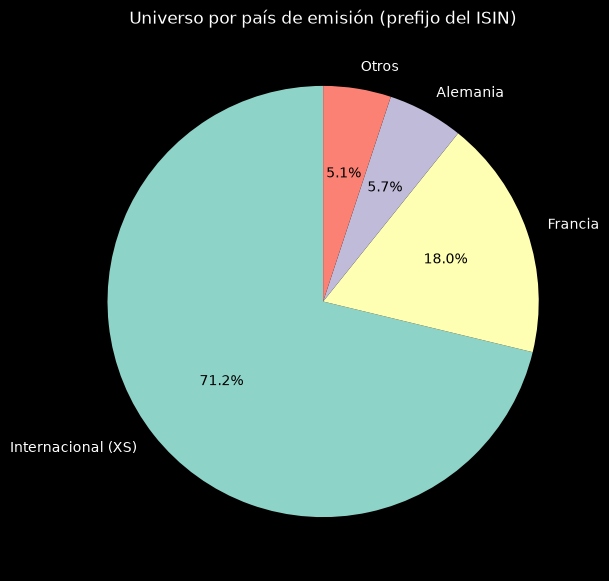

In [11]:
# País de emisión de los bonos según el prefijo de su ISIN
# (XS = emisión internacional en Euroclear/Clearstream; no indica la nacionalidad de la empresa)
paises_isin = {
    'XS': 'Internacional (XS)', 'FR': 'Francia', 'DE': 'Alemania', 'BE': 'Bélgica',
    'ES': 'España', 'CH': 'Suiza', 'AT': 'Austria', 'DK': 'Dinamarca',
    'PT': 'Portugal', 'IT': 'Italia', 'FI': 'Finlandia', 'SK': 'Eslovaquia',
}
pais_emision = pd.Series(universo.index.str[:2], index=universo.index).map(paises_isin)
conteo = pais_emision.value_counts()
print(conteo.to_string())

# Agrupamos los países con menos del 2% de los bonos en "Otros" para que el gráfico se lea bien
pequenos = conteo[conteo / conteo.sum() < 0.02]
conteo_graf = conteo.drop(pequenos.index)
conteo_graf['Otros'] = pequenos.sum()

fig, ax = plt.subplots(figsize=(7, 7))
_, _, porcentajes = ax.pie(conteo_graf, labels=conteo_graf.index, autopct='%1.1f%%', startangle=90)
for texto in porcentajes:
    texto.set_color('black')       # porcentajes en negro: se leen bien sobre colores claros
ax.set_title('Universo por país de emisión (prefijo del ISIN)')
plt.show()

**País de emisión.** El 71,2% de los bonos tiene ISIN con prefijo **XS**: son emisiones internacionales registradas en Euroclear o Clearstream, y el prefijo no indica la nacionalidad del emisor. Entre los de prefijo nacional destacan Francia (18,0%) y Alemania (5,7%). El universo incluye emisores de muchos países, también de fuera de la zona euro (p. ej. empresas estadounidenses como American Tower o Netflix que emiten en euros). Los datos no incluyen el país de riesgo de cada emisor (*Country of Risk*), así que no podemos medir con precisión la concentración geográfica.

#### <font color=#808080>Ratings (Riesgo de crédito)</font>

Rating
AAA       4
AA+       6
AA       20
AA-      96
A+      180
A       222
A-      363
BBB+    415
BBB     300
BBB-    176
BB+       8
NR      372
Name: count, dtype: int64
Bonos sin dato de rating (NaN): 3


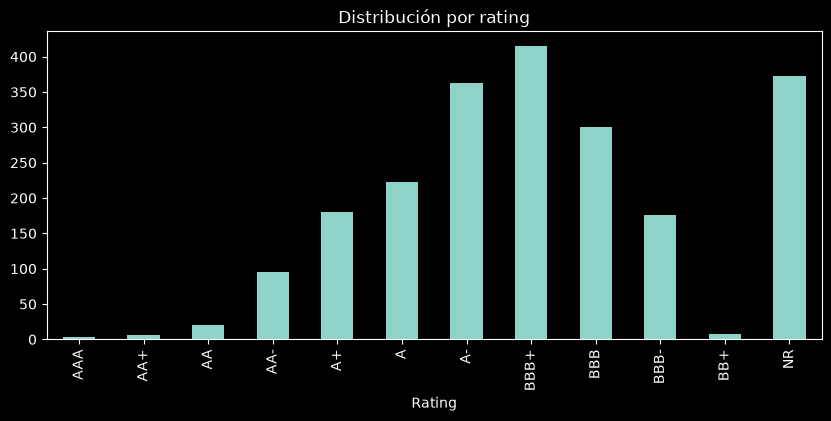

In [12]:
# Escala de ratings de mejor a peor, para ordenar las tablas y gráficos
escala = ['AAA', 'AA+', 'AA', 'AA-', 'A+', 'A', 'A-',
          'BBB+', 'BBB', 'BBB-',                    # hasta aquí: Investment Grade
          'BB+', 'BB', 'BB-', 'B+', 'B', 'B-',      # High Yield
          'NR']                                      # sin rating

# Nº de bonos por rating en el orden de la escala (eliminamos los que no aparecen)
ratings = universo['Rating'].value_counts().reindex(escala).dropna().astype(int)
print(ratings)
print(f"Bonos sin dato de rating (NaN): {universo['Rating'].isna().sum()}")

ratings.plot(kind='bar', figsize=(10, 4))
plt.title('Distribución por rating')
plt.show()

In [13]:
# Clasificamos cada bono en IG / HY / Sin rating
grado_inversion = escala[:10]   # de AAA a BBB-

def clasificar_rating(rating):
    """Devuelve 'IG', 'HY' o 'Sin rating' según el rating del bono."""
    if pd.isna(rating) or rating == 'NR':
        return 'Sin rating'
    return 'IG' if rating in grado_inversion else 'HY'

universo['Categoria'] = universo['Rating'].apply(clasificar_rating)
universo['Categoria'].value_counts()

Categoria
IG            1782
Sin rating     375
HY               8
Name: count, dtype: int64

In [14]:
# ¿Qué probabilidad de impago a 1 año tiene cada categoría?
universo.groupby('Categoria')['PD 1YR'].describe()


,count,mean,std,min,25%,50%,75%,max
Categoria,,,,,,,,
HY,8.0,0.007917,0.010345,2.872080e-06,0.000026,0.001057,0.020395,0.020395
IG,1765.0,0.003777,0.008857,2.944640e-12,0.000014,0.000118,0.001036,0.063122
Sin rating,369.0,0.002893,0.005606,1.082270e-09,0.000015,0.000298,0.002114,0.031020


In [15]:
# ¿De qué sectores son los bonos sin rating?
sin_rating = universo[universo['Categoria'] == 'Sin rating']
print(sin_rating['Industry Sector'].value_counts())
print(f"Financieros: {(sin_rating['Industry Sector'] == 'Financial').mean() * 100:.1f}%")

Industry Sector
Financial                 189
Industrial                 45
Consumer, Non-cyclical     43
Utilities                  38
Consumer, Cyclical         15
Technology                 15
Basic Materials            11
Communications             10
Energy                      9
Name: count, dtype: int64
Financieros: 50.4%


- El universo es casi todo **Investment Grade** (1.782 bonos; 82%); los ratings más frecuentes son BBB+ (415) y A- (363). La calidad crediticia media es buena, pero el grueso está en la parte baja del IG (BBB+ a BBB-: 891 bonos), donde una rebaja de rating puede llevar al bono a HY.
- Riesgo "fallen angel" : En expansiones económicas tranquilas, las tasas anuales de rebaja de calificación de los bonos BBB- suelen caer al rango del 4 % al 6 %. Durante recesiones graves o crisis crediticias (como las de 2008-2009 o 2020), la tasa puede dispararse por encima del 15 % al 20 %..
- Solo hay **8 bonos High Yield**, todos BB+ (el mejor escalón HY).
- Hay **375 bonos sin rating** (372 NR + 3 sin dato), la mitad de ellos financieros.
- La PD mediana a 1 año de los sin rating (0,000298) está **entre la de los IG (0,000118) y la de los HY (0,001057)**, en las unidades del fichero: su riesgo de impago estimado es algo mayor que el de los IG, pero muy inferior al de los HY. Usamos la mediana en lugar de la media porque la PD tiene valores extremos que distorsionan la media (en IG, media 0,003777 vs mediana 0,000118).
- **Decisión:** por prudencia, en el mandato **tratamos los sin rating como HY**, ya que no podemos verificar su calidad crediticia y así nunca incumpliríamos el límite del 10% en HY.

#### <font color=#808080>Riesgo de liquidez - Horquillas y nominal vivo</font>

In [16]:
# Horquilla bid-ask en puntos de precio
universo['Horquilla'] = universo['Ask Price'] - universo['Bid Price']

# Nominal vivo en millones, más fácil de leer
universo['Nominal_mill'] = universo['Outstanding Amount'] / 1e6

universo[['Horquilla', 'Nominal_mill']].describe()

,Horquilla,Nominal_mill
count,2165.000000,2165.000000
mean,0.235440,744.580655
std,0.145767,308.231911
min,0.029200,250.003000
25%,0.129300,500.000000
50%,0.201900,700.000000
75%,0.307590,1000.000000
max,1.537550,3000.000000


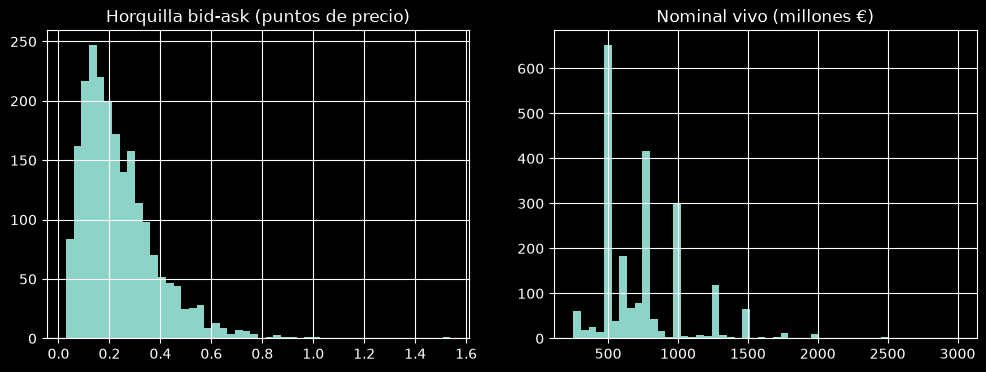

In [17]:
# Histogramas de horquilla y nominal vivo
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

universo['Horquilla'].hist(bins=50, ax=ax[0])
ax[0].set_title('Horquilla bid-ask (puntos de precio)')

universo['Nominal_mill'].hist(bins=50, ax=ax[1])
ax[1].set_title('Nominal vivo (millones €)')

plt.show()

In [18]:
# Horquilla mediana por categoría de rating
print(universo.groupby('Categoria')['Horquilla'].median(), '\n')

# Bonos excluidos por el mandato por tamaño (≤ 500 millones)
pequenos = (universo['Nominal_mill'] <= 500).sum()
print(f'Bonos con nominal ≤ 500M: {pequenos} ({pequenos / len(universo) * 100:.1f}%)')

Categoria
HY            0.12945
IG            0.19921
Sin rating    0.22599
Name: Horquilla, dtype: float64 

Bonos con nominal ≤ 500M: 767 (35.4%)


- Las horquillas bid-ask son **estrechas** (mediana ≈ 0,20 puntos, máximo 1,54), en línea con lo que suele observarse en crédito corporativo IG en euros. Como referencia, en la deuda pública alemana (*Bunds*), el mercado más líquido de la zona euro, la horquilla suele ser de solo **1–3 céntimos** (0,01–0,03 puntos), unas 10 veces menor: el crédito corporativo es líquido, pero bastante menos que la deuda soberana. El mínimo es positivo (0,03), así que no hay horquillas negativas: los datos de Bid y Ask son coherentes.
- Los bonos sin rating tienen una horquilla similar a los IG, lo que respalda que su liquidez no es peor. Los 8 HY no parecen menos líquidos, pero son demasiado pocos para concluir.
- El **35,4%** de las emisiones (767 bonos) tiene un nominal ≤ 500 millones y queda fuera del mandato: esta restricción reduce mucho el universo invertible antes de aplicar las demás.
- *Mejora propuesta:* medir la horquilla en pb de rentabilidad (horquilla / duración) en lugar de en puntos de precio. 0,20 puntos equivalen a ~20 pb de rentabilidad en un bono a 1 año, pero solo a ~2 pb en uno a 10 años, así que en puntos de precio los bonos largos parecen menos líquidos de lo que son. Podría calcularse con las duraciones de la sección 4.

#### <font color=#808080>Resto de información</font>

En esta sección, analizamos el resto de ficheros para ver qué información tenemos y, en caso de haber *gaps*, limpiar los datos antes de trabajar con ellos.

##### <font color=#CC6600>Precios bonos universo</font>

In [19]:
# Cargamos los precios históricos: filas = bonos, columnas = fechas
precios = pd.read_csv(
    RUTA_DATOS + 'precios_historicos_universo.csv',
    sep=';',
    index_col=0,             # la primera columna (identificador del bono) será el índice
    na_values=['#N/D'],      # marcador de "sin dato" -> NaN
    encoding='utf-8-sig'
)

# Transponemos: filas = fechas, columnas = bonos
precios = precios.T

# Convertimos el índice (texto) a fechas
precios.index = pd.to_datetime(precios.index, format='%d/%m/%Y')

# Los identificadores vienen como 'XS0161488498 Corp': nos quedamos solo con el ISIN
precios.columns = precios.columns.str.replace(' Corp', '', regex=False)

print(precios.shape)
print('¿Mismos bonos que en el universo?', set(precios.columns) == set(universo.index))

(1097, 2165)
¿Mismos bonos que en el universo? True


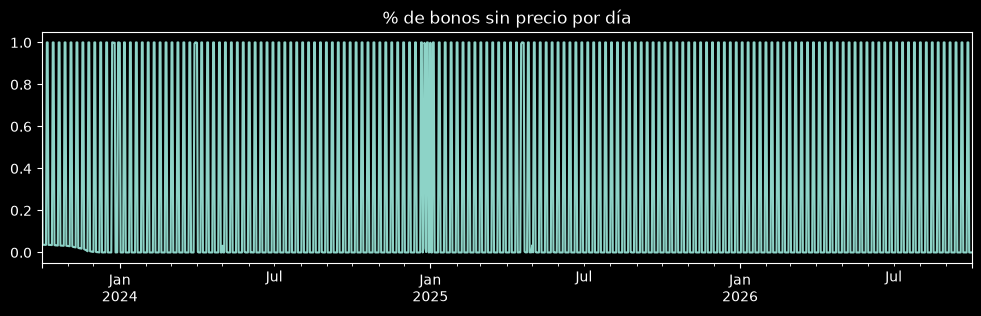

Días sin mercado: 323
De ellos, fines de semana: 313
Festivos entre semana: ['25/12/2023', '26/12/2023', '01/01/2024', '29/03/2024', '01/04/2024', '25/12/2024', '26/12/2024', '01/01/2025', '18/04/2025', '21/04/2025']


In [20]:
# Porcentaje de bonos sin precio en cada fecha
pct_nan_dia = precios.isna().mean(axis=1)

pct_nan_dia.plot(figsize=(12, 3))
plt.title('% de bonos sin precio por día')
plt.show()

# Días en los que (casi) ningún bono tiene precio: fines de semana y festivos
dias_sin_mercado = pct_nan_dia > 0.9
print(f'Días sin mercado: {dias_sin_mercado.sum()}')
print(f'De ellos, fines de semana: {(dias_sin_mercado & (precios.index.day_of_week >= 5)).sum()}')

# ¿Cuáles de esos días NO son fin de semana? (day_of_week: 0 = lunes ... 6 = domingo)
festivos = precios.index[dias_sin_mercado & (precios.index.day_of_week < 5)]
print('Festivos entre semana:', list(festivos.strftime('%d/%m/%Y')))

In [21]:
# Eliminamos fines de semana y festivos
precios = precios.loc[~dias_sin_mercado]
print(f'Días hábiles: {len(precios)}')

# ¿Qué bonos empiezan a cotizar más tarde? (emitidos después de oct-2023)
primer_precio = precios.apply(lambda serie: serie.first_valid_index())
emitidos_tarde = primer_precio[primer_precio > precios.index[0]]
print(f'Bonos que empiezan a cotizar después del inicio: {len(emitidos_tarde)}')

# Comprobamos que coinciden con su fecha de emisión
pd.DataFrame({
    'Primer precio': emitidos_tarde,
    'Fecha emisión': universo.loc[emitidos_tarde.index, 'Issue date']
}).head(10)

Días hábiles: 774
Bonos que empiezan a cotizar después del inicio: 79


,Primer precio,Fecha emisión
XS2698045130,2023-10-17,2023-09-29
XS2690050682,2023-10-06,2023-10-12
FR001400LCK1,2023-10-12,2023-10-18
XS2705604234,2023-10-13,2023-10-18
XS2698998593,2023-10-17,2023-10-23
XS2707169111,2023-10-17,2023-10-23
FR001400KSZ7,2023-10-18,2023-10-25
XS2704918478,2023-10-20,2023-10-25
XS2708354811,2023-10-19,2023-10-25
XS2661068234,2023-10-26,2023-10-30


In [22]:
# Control de calidad de los precios: tras quitar fines de semana y festivos
# (no son huecos de datos) y ANTES de rellenar huecos con ffill (que los ocultaría)
cc_precios = fa.control_calidad_precios(precios)
cc_precios.to_csv(RUTA_RESULTS + 'control_calidad_precios.csv', sep=';')

print(f"Bonos con algún missing: {(cc_precios['NumMissing'] > 0).sum()}")
print(f"Bonos con huecos entre cotizaciones: {(cc_precios['HuecosEntreCotizaciones'] > 0).sum()}")
print(f"Bonos que dejan de cotizar antes del final: {(cc_precios['FechaFin'] < precios.index[-1]).sum()}")
cc_precios.describe()

Bonos con algún missing: 222
Bonos con huecos entre cotizaciones: 147
Bonos que dejan de cotizar antes del final: 0


,NumObservaciones,NumMissing,Minimo,Maximo,FechaInicio,FechaFin,HuecosEntreCotizaciones
count,2165.000000,2165.000000,2165.000000,2165.000000,2165,2165,2165.000000
mean,772.727483,1.272517,87.054551,98.423157,2023-10-03 13:38:06.374134,2026-10-01 00:00:00,0.131178
min,723.000000,0.000000,42.695760,63.295000,2023-10-02 00:00:00,2026-10-01 00:00:00,0.000000
25%,774.000000,0.000000,80.873000,94.298000,2023-10-02 00:00:00,2026-10-01 00:00:00,0.000000
50%,774.000000,0.000000,88.004000,98.605320,2023-10-02 00:00:00,2026-10-01 00:00:00,0.000000
75%,774.000000,0.000000,95.402000,103.815000,2023-10-02 00:00:00,2026-10-01 00:00:00,0.000000
max,774.000000,51.000000,120.502000,240.270000,2023-12-08 00:00:00,2026-10-01 00:00:00,31.000000
std,6.250294,6.250294,9.829287,8.705512,NaN,NaN,0.855758


In [23]:
# Evidencias de los problemas de calidad detectados en los precios

# 1) Huecos entre cotizaciones: total y bono con más huecos
huecos = cc_precios['HuecosEntreCotizaciones']
print(f'Huecos totales: {huecos.sum()} | Bono con más huecos: {huecos.idxmax()} ({huecos.max()} días)')

# 2) Precio máximo anómalo: qué bono es y en qué fecha
isin_max = cc_precios['Maximo'].idxmax()
print(f"Precio máximo: {universo.loc[isin_max, 'Description']} ({isin_max}) = "
      f"{cc_precios.loc[isin_max, 'Maximo']} el {precios[isin_max].idxmax().date()}")

# 3) Saltos anómalos (spikes): variación diaria > 5% que revierte al día siguiente
rent_diaria = precios.ffill().pct_change(fill_method=None)
siguiente = rent_diaria.shift(-1)
spikes = (rent_diaria.abs() > 0.05) & (siguiente.abs() > 0.05) & (rent_diaria * siguiente < 0)
grandes = rent_diaria.abs() > 0.10
print(f'Saltos que revierten: {spikes.sum().sum()} en {(spikes.sum() > 0).sum()} bonos')
print(f'Movimientos diarios > 10%: {grandes.sum().sum()} en {(grandes.sum() > 0).sum()} bonos')

# 4) Precios anteriores a la fecha de emisión (mercado gris)
emision = universo.loc[precios.columns, 'Issue date']
antes_emision = precios.apply(
    lambda serie: serie.loc[:emision[serie.name] - pd.Timedelta(days=1)].notna().any()
)
print(f'Bonos con precios antes de su fecha de emisión: {antes_emision.sum()}')

# Días de mercado gris: desde el primer precio del bono hasta su fecha de emisión
bonos_gris = antes_emision[antes_emision].index
dias_gris = (emision[bonos_gris] - cc_precios.loc[bonos_gris, 'FechaInicio']).dt.days
print(f'Días entre el primer precio y la emisión: mínimo {dias_gris.min()}, '
      f'mediana {dias_gris.median():.0f}, máximo {dias_gris.max()}')


# ¿Algún spike cae en una fecha de fin de mes (fechas de rebalanceo del backtest)?
fin_mes_cc = fa.fechas_fin_de_mes(precios.index)
print(f'Spikes en fechas de fin de mes: {spikes.loc[spikes.index.isin(fin_mes_cc)].sum().sum()}')

Huecos totales: 284 | Bono con más huecos: XS2698045130 (31 días)
Precio máximo: ALVGR 1 ⅜ 04/21/31 (DE000A180B80) = 240.27 el 2024-12-24
Saltos que revierten: 46 en 40 bonos
Movimientos diarios > 10%: 65 en 31 bonos
Bonos con precios antes de su fecha de emisión: 85
Días entre el primer precio y la emisión: mínimo 2, mediana 5, máximo 9
Spikes en fechas de fin de mes: 0


#### Control de calidad: conclusiones

**Universo (`control_calidad_universo.csv`).** 21 características y ISIN único (2.165 valores distintos). Solo hay *missing* en 5 columnas: `Next Call Date` (583: bonos no callable, es correcto), `PD 1YR` (23), `Maturity` y `Penultimate Coupon Date` (18: los perpetuos) y `Rating` (3). Todos los bonos están en EUR. `Description` tiene 2.163 valores únicos: hay dos pares de bonos distintos con la misma descripción, sin impacto porque identificamos por ISIN.

**Precios (`control_calidad_precios.csv`).** Tras quitar fines de semana y festivos quedan 774 días hábiles y ningún bono deja de cotizar antes del final. 222 bonos tienen algún *missing* (sobre todo por empezar a cotizar más tarde) y 147 tienen huecos reales entre cotizaciones (284 en total, máximo 31 días en XS2698045130). Las tablas de control se generan con los datos originales, antes de cualquier tratamiento.

**Problemas de calidad detectados:**

| Problema | Tratamiento | Bonos afectados | Consecuencia de no tratarlo |
|---|---|---|---|
| **Precios anómalos (*spikes*)**: saltos que revierten al día siguiente; p. ej. ALVGR 1⅜ 2031 pasa de ~91,7 a **240,27** el 24/12/2024 y vuelve a ~91,5 | **Aplicado:** marcamos como NaN los saltos > 5% que revierten al día siguiente y los rellenamos con el último precio válido (función `filtrar_spikes`) | 46 saltos en 40 bonos (65 movimientos diarios > 10% en 31 bonos) | Rentabilidades y volatilidades diarias falsas (p. ej. en coberturas o correlaciones). En el backtest mensual no hay impacto: ningún spike cae en un fin de mes (lo hemos comprobado) |
| **Precios anteriores a la fecha de emisión** (mercado gris): el bono ya cotiza entre la fijación de su precio y su fecha de emisión (liquidación), normalmente a T+5. Son precios reales, no errores: entre 2 y 9 días antes de la emisión (mediana, 5) | **Aplicado:** en el backtest, cada bono cuenta solo desde su `Issue date`, ya que antes no se puede tener el bono ni cobrar su cupón | 85 bonos | *Look-ahead bias*: la cartera "compraría" bonos que todavía no se habían emitido |
| **Huecos entre cotizaciones** | **Aplicado:** *forward fill*, manteniendo el último precio disponible | 147 bonos (284 días) | Rentabilidades NaN o bonos que entran y salen de la cartera; los precios "planos" infravaloran la volatilidad |
| **Ratings y PD ausentes**: 372 NR + 3 sin rating; 23 sin PD | **Decisión para la sección 6:** tratar los bonos sin rating como HY en el mandato (criterio prudente) | 375 sin rating; 23 sin PD | Podríamos incumplir el límite de HY del 10% y subestimar el riesgo de crédito |
| **Fechas call ya pasadas** (call ejercitable no ejercida) | **Aplicado:** valorar a vencimiento final; el perpetuo BNFP, al próximo cupón (función `fecha_vencimiento_efectiva`) | 11 bonos | Valorar a una fecha ya pasada y obtener z-spreads absurdos en bonos bajo la par |

In [24]:
# Tratamiento de los spikes: los marcamos como NaN para que el forward fill
# de la celda siguiente los sustituya por el último precio válido.
# (Las tablas de control de calidad ya se han generado con los datos originales.)
# Guardamos una copia de los precios antes del filtro, para comparar en un gráfico
precios_sin_filtrar = precios.copy()
precios, spikes_detectados = fa.filtrar_spikes(precios)

print(f'Precios anómalos eliminados: {spikes_detectados.sum().sum()} '
      f'en {(spikes_detectados.sum() > 0).sum()} bonos')
print(f"Nuevo precio máximo de ALVGR 1⅜ 2031: {precios['DE000A180B80'].max()}")

Precios anómalos eliminados: 46 en 40 bonos
Nuevo precio máximo de ALVGR 1⅜ 2031: 94.172


Huecos rellenados: 330


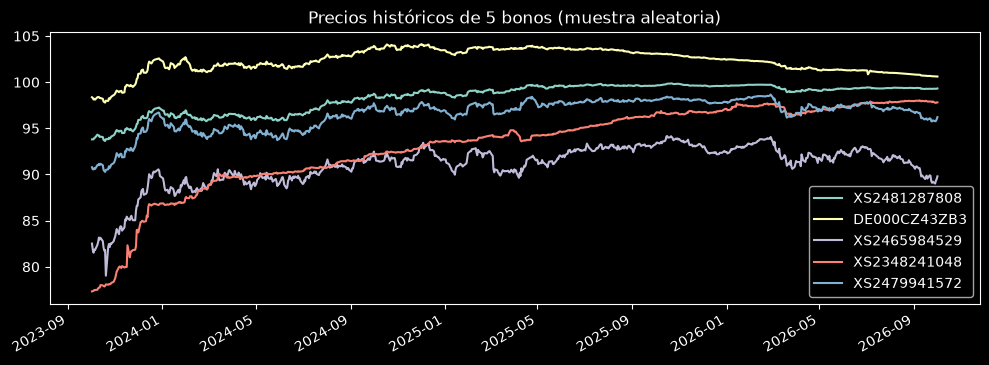

In [25]:
# Rellenamos los huecos puntuales con el último precio disponible
# (ffill no rellena los NaN iniciales: los bonos aún no emitidos siguen sin precio)
huecos_antes = precios.isna().sum().sum()
precios = precios.ffill()
print(f'Huecos rellenados: {huecos_antes - precios.isna().sum().sum()}')

# Evolución de precios de 5 bonos al azar (random_state fija la muestra)
precios.sample(5, axis=1, random_state=42).plot(figsize=(12, 4))
plt.title('Precios históricos de 5 bonos (muestra aleatoria)')
plt.show()

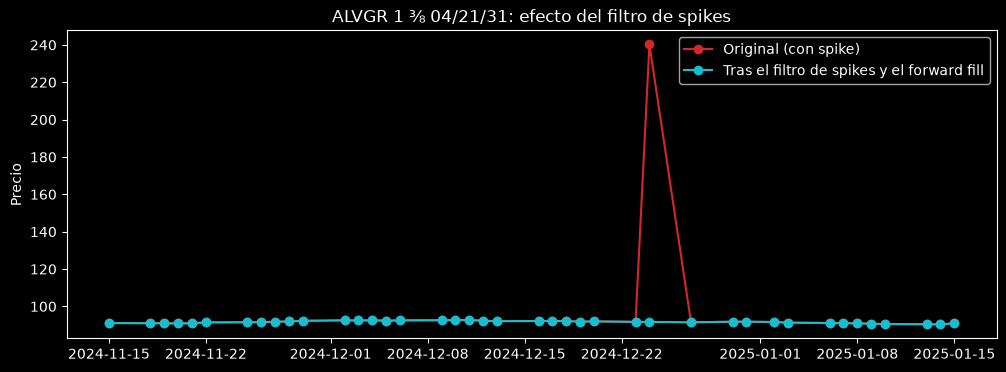

In [26]:
# Efecto del filtro de spikes: ALVGR 1⅜ 2031 antes y después de la limpieza
isin_ejemplo = 'DE000A180B80'
ventana = slice('2024-11-15', '2025-01-15')      # alrededor del spike del 24/12/2024

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(precios_sin_filtrar.loc[ventana, isin_ejemplo], marker='o', color='tab:red',
        label='Original (con spike)')
ax.plot(precios.loc[ventana, isin_ejemplo], marker='o', color='tab:cyan',
        label='Tras el filtro de spikes y el forward fill')
ax.set_title(f"{universo.loc[isin_ejemplo, 'Description']}: efecto del filtro de spikes")
ax.set_ylabel('Precio')
ax.legend()
plt.show()

**Limpieza de precios.**
- Hay **323 días** sin precio para ningún bono: **313 fines de semana y 10 festivos** de mercado (Navidad, 26 de diciembre, Año Nuevo, Viernes Santo y Lunes de Pascua). No son huecos de datos, así que los eliminamos y quedan **774 días hábiles**.
- 79 bonos empiezan a cotizar más tarde por su fecha de emisión; sus NaN iniciales se mantienen (el *forward fill* no rellena hacia atrás).
- Antes del *forward fill* eliminamos los **46 spikes** detectados en el control de calidad (en 40 bonos), p. ej. el 240,27 de ALVGR 1⅜ 2031.
- El resto de huecos (284 días en 147 bonos) se rellenan con el **último precio disponible**, suponiendo que sin negociación el precio no cambia.
- Hemos comprobado, ejecutando el backtest con y sin el filtro de spikes, que **no altera sus resultados** (+15,32% la cartera y +12,74% el benchmark en ambos casos), ya que ningún spike cae en un fin de mes.
- **Comprobación visual:** el gráfico de 5 bonos al azar muestra que, tras la limpieza, las series son continuas, sin saltos anómalos y en rangos de precio razonables. El segundo gráfico muestra el efecto del filtro sobre el caso más extremo: el precio de ALVGR 1⅜ 2031 pasa de ~91,7 a 240,27 el 24/12/2024 y vuelve a ~91,5 al día siguiente; tras el filtro, ese día toma el precio anterior.

##### <font color=#CC6600>Otros precios</font>

Para terminar con el análisis de datos, falta lo leído en los ficheros de *precios_historicos_varios.csv* y *curvaESTR.csv*.

ITRX EUR CDSI GEN 5Y Corp      15
ITRX XOVER CDSI GEN 5Y Corp    15
DU1 Comdty                     12
OE1 Comdty                     12
RX1 Comdty                     12
RECMTREU Index                  0
dtype: int64
¿Mismas fechas que precios? False


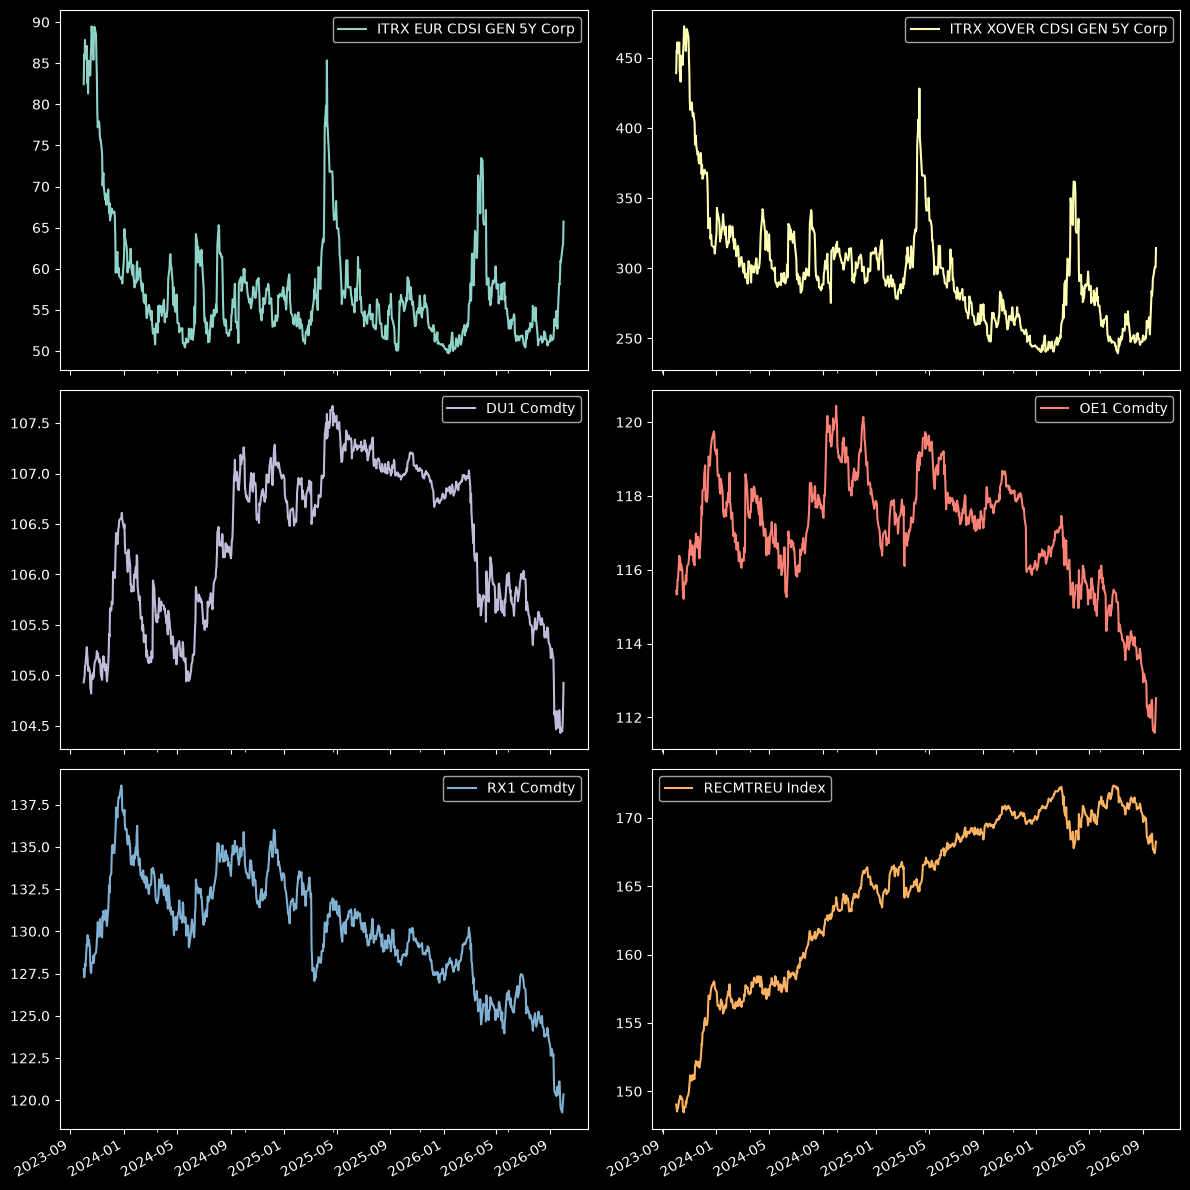

In [27]:
# Cargamos índices de crédito (iTraxx), futuros (DU1, OE1, RX1) y benchmark (RECMTREU)
varios = pd.read_csv(
    RUTA_DATOS + 'precios_historicos_varios.csv',
    sep=';', index_col=0, na_values=['#N/D'], encoding='utf-8-sig'
)
varios.index = pd.to_datetime(varios.index, format='%d/%m/%Y')

# Huecos por serie
print(varios.isna().sum())

# Rellenamos con el último valor disponible
varios = varios.ffill()

# ¿Las fechas coinciden con las de los precios de los bonos?
print('¿Mismas fechas que precios?', varios.index.equals(precios.index))

# Un gráfico por serie (escalas muy distintas)
varios.plot(subplots=True, figsize=(12, 12), layout=(3, 2))
plt.tight_layout()
plt.show()

**Qué muestran los gráficos (oct-2023 a oct-2026):**
- **Crédito (iTraxx Main y Crossover):** los dos índices se mueven juntos. Los spreads se estrechan con fuerza desde su máximo de octubre de 2023 (Main 89 pb, Crossover 473 pb) hasta sus mínimos de 2026 (Main ~50 pb en enero, Crossover ~239 pb en julio), y repuntan en los últimos meses hasta 66 y 314 pb. El Crossover (*high yield*) es mucho más volátil que el Main (*investment grade*). Se ven ampliaciones bruscas puntuales, como en junio de 2024 y abril de 2025, que coinciden con episodios de tensión en los mercados (elecciones anticipadas en Francia y anuncio de aranceles en EE. UU.).
- **Futuros sobre deuda alemana:** el Schatz (DU1) apenas varía (~105) porque es el tramo corto; el Bobl (OE1) y sobre todo el Bund (RX1) bajan en el periodo (el Bund de ~138 a finales de 2023 a ~120), es decir, **suben los tipos a medio y largo plazo**. La mayor caída diaria del Bund (−2,4%, en marzo de 2025) coincide con el anuncio del plan fiscal alemán.
- **Benchmark RECMTREU:** sube de forma bastante continua de 149 a 168 (+12,7%), con un máximo de 172 en junio de 2026 y una ligera caída final, en línea con el repunte de los spreads.
- **Saltos que no son de mercado:** las series de futuros e iTraxx son **genéricas** (siempre el contrato o la serie más reciente). En los cambios de contrato (*roll*) aparecen saltos que no son movimientos reales: p. ej. en marzo y septiembre de 2024 en los futuros, o el 20 de septiembre de 2024 y el 20 de marzo de 2026 en el iTraxx (fechas de cambio de serie). Hay que tenerlo en cuenta si se calculan rentabilidades con estas series.

Diferencia máxima: 6.765132900543591e-07


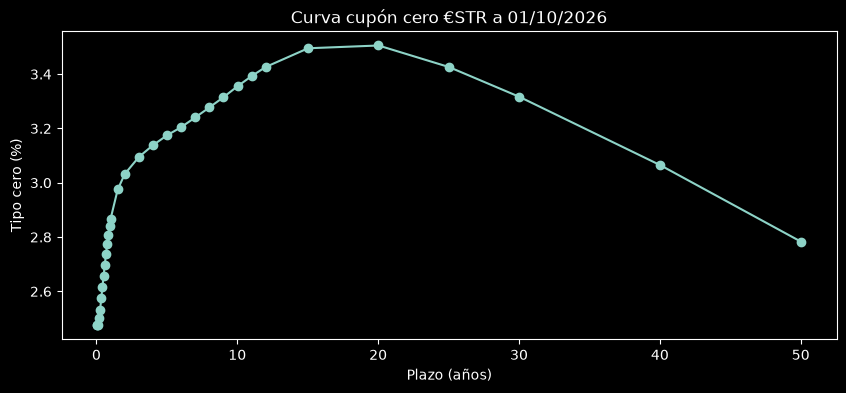

In [28]:
# Cargamos la curva €STR a 01/10/2026
curva = pd.read_csv(RUTA_DATOS + 'curvaESTR.csv', sep=';')
curva['Date'] = pd.to_datetime(curva['Date'], format='%d/%m/%Y')

# Plazo en años desde la fecha de análisis (base Act/365)
curva['Plazo'] = (curva['Date'] - fecha_analisis).dt.days / 365

# Comprobación: ¿el factor de descuento sale de capitalización continua?  DF = exp(-z·t)
curva['DF_check'] = np.exp(-curva['Zero Rate'] / 100 * curva['Plazo'])
print('Diferencia máxima:', (curva['DF_check'] - curva['Discount']).abs().max())

# Gráfico de la curva cero
curva.plot(x='Plazo', y='Zero Rate', marker='o', figsize=(10, 4), legend=False)
plt.title('Curva cupón cero €STR a 01/10/2026')
plt.xlabel('Plazo (años)')
plt.ylabel('Tipo cero (%)')
plt.show()

- **Índices y futuros:** pocos huecos (15 días en cada iTraxx y 12 en cada futuro), rellenados con el último valor disponible; el benchmark RECMTREU está completo. Las fechas coinciden con las de los precios de los bonos.
- **Curva €STR (33 nodos hasta 2076):** muy empinada en el tramo corto (del ~2,5% al ~3,0% en 1–2 años: el mercado descuenta subidas del €STR), sube suavemente hasta un máximo de ~3,5% en 15–20 años y **baja en el tramo muy largo** (~2,8% a 50 años), por la fuerte demanda de plazos largos de fondos de pensiones y aseguradoras para cubrir sus pasivos.
Los factores de descuento cumplen $DF = e^{-z \cdot t}$ con base ACT/365 (diferencia máxima ≈ $7 \cdot 10^{-7}$): la curva está en **capitalización continua**, y así la usamos para valorar.
- Como solo hay 33 plazos, necesitamos **interpolar** para descontar flujos en fechas intermedias (sección 2). La mayoría de nuestros bonos vence en menos de 15 años, en el tramo ascendente de la curva.

#### <font color=#808080>Conclusiones</font>

**Universo.** 2.165 bonos corporativos en EUR de 605 emisores, mayoritariamente de cupón fijo (85%) y deuda senior. El 73% son callable y hay 18 perpetuos (híbridos subordinados).

**Riesgos principales:**
- **Concentración:** el 44,8% del universo es del sector financiero, con un peso relevante de la banca francesa. Diversificado por número de emisores, pero no por sectores.
- **Crédito:** 82% Investment Grade, con el grueso en la parte baja (BBB+ a BBB-); solo 8 HY (BB+) y 375 bonos sin rating, que tratamos como HY por prudencia.
- **Liquidez:** horquillas estrechas (mediana ≈ 0,20 puntos); el 35,4% de las emisiones tiene un nominal ≤ 500M y queda fuera del mandato.

**Calidad de datos:** los datos son en general consistentes (ISIN único, una sola divisa, sin horquillas negativas), pero hemos detectado *spikes* en los precios, precios anteriores a la emisión, huecos de cotización, ratings y PD ausentes, y fechas call ya pasadas (ver tabla de control de calidad).

**Decisiones para el resto del trabajo:**
- **Precios:** eliminamos fines de semana y festivos (774 días hábiles), filtramos los 46 *spikes* y rellenamos los huecos con *forward fill*.
- **Backtest:** cada bono cuenta solo desde su fecha de emisión, para evitar *look-ahead bias*.
- **Valoración:** a la próxima fecha call (perpetuos incluidos). Si la call ya ha pasado, a vencimiento (el perpetuo BNFP, al próximo cupón).
- **Curva:** €STR en capitalización continua ACT/365, con interpolación exponencial de los factores de descuento.
- **Mandato:** los bonos sin rating cuentan como HY.

### <font color=#336699>2. Valoración</font>

**Valoración de los bonos del universo** utilizando la curva de descuento y bajo ciertas asunciones. Comparación de estos precios con los precios de mercado.

En esta sección, valoraremos los bonos utilizando la curva. Para ello, crea una función (puedes hacerlo en un .py aparte) que con las **características del bono, la curva y un spread de crédito** para que devuelva la valoración del bono (incluyendo **precio limpio, cupón corrido y precio sucio**).

Si asumimos que el **spread de crédito es 0**, y la ejecutamos para el 01/10/2026:
- ¿Qué observas si comparas los precios obtenidos y los precios de mercado? 
- ¿Crees que la diferencia se debe a un factor relacionado sólo con el riesgo crediticio?
- ¿Qué otros factores influyen en ese spread?

Para la valoración, haz las siguientes simplificaciones:

- Asume que el vencimiento de los bonos perpetuos (para los que no hay vencimiento) es la próxima fecha call.
- Asume que todos aquellos bonos que tengan call serán calleados. Por lo tanto, usa la fecha call como fecha de vencimiento.
- Asume que los cupones son fijos hasta vencimiento (aunque alguno cambie a lo largo de la vida del bono).
- Usa la base de cálculo ACT/365. No tengas en cuenta la convención de día hábil.

Ten en cuenta que necesitarás una función de interpolación también. Interpola los factores de descuento exponencialmente.

**Guarda en "results" una tabla llamada "valoracion.csv" que contenga:**

- ISIN
- PrecioMercado
- PrecioSucioCalculado
- CuponCorrido
- PrecioLimpioCalculado
- DiferenciaMecadoCalculo
- DiferenciaPct


In [29]:
# Establecemos la fecha
fecha_valor = datetime.datetime(2026,10,1)

In [30]:
# Convertimos la fecha de valoración al tipo de fecha de pandas
fecha_valor = pd.Timestamp(fecha_valor)

# Calculamos el vencimiento efectivo de cada bono (fila a fila: axis=1)
universo['Vto_efectivo'] = universo.apply(
    lambda bono: fa.fecha_vencimiento_efectiva(bono, fecha_valor), axis=1
)

# Comprobación: los 11 bonos con la fecha call ya pasada
call_pasada = universo['Next Call Date'] <= fecha_valor
universo.loc[call_pasada, ['Description', 'Next Call Date', 'Maturity', 'Vto_efectivo']]

,Description,Next Call Date,Maturity,Vto_efectivo
ISIN,,,,
XS1186176571,HTHROW 1 ½ 02/11/30,2026-02-11,2030-02-11,2030-02-11
XS1405762805,TKAAV 1 ½ 12/07/26,2026-09-07,2026-12-07,2026-12-07
XS1531347661,BDX 1.9 12/15/26,2026-09-15,2026-12-15,2026-12-15
XS1532779748,ZBH 2.425 12/13/26,2026-09-13,2026-12-13,2026-12-13
FR0013302809,SUFP 0 ⅞ 12/13/26,2026-09-13,2026-12-13,2026-12-13
XS2081500907,FCCSER 1.661 12/04/26,2026-09-23,2026-12-04,2026-12-04
XS2193974701,WMG 2 ¾ 07/15/28,2025-11-28,2028-07-15,2028-07-15
XS2367081523,WMG 2 ¼ 08/15/31,2026-08-15,2031-08-15,2031-08-15
FR0014005EJ6,BNFP 1 PERP,2026-09-16,NaT,2026-12-16


Valorados a fecha call: 1572
Plazo efectivo mínimo (años): 0.014
Bono con plazo mínimo: ARRFP 1 ¼ 01/06/27
Plazo máximo (años): 34.47 - LLY 1 ⅜ 09/14/61
Último nodo de la curva (años): 50.05
Bonos con plazo efectivo <= 7 años: 91.0%


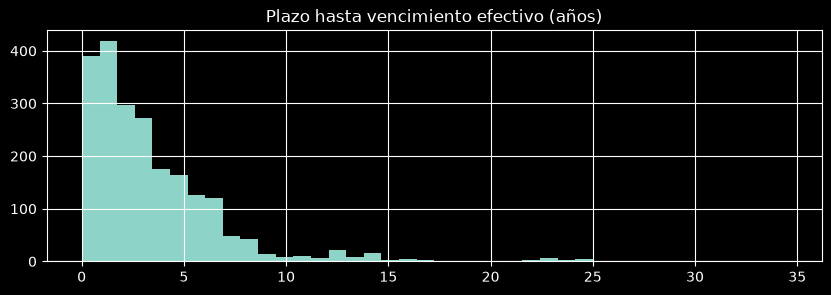

In [31]:
# Plazo efectivo en años (ACT/365) y número de bonos según el tipo de vencimiento
universo['Plazo_efectivo'] = (universo['Vto_efectivo'] - fecha_valor).dt.days / 365

print('Valorados a fecha call:', (universo['Vto_efectivo'] != universo['Maturity']).sum())
print('Plazo efectivo mínimo (años):', universo['Plazo_efectivo'].min().round(3))
# Evidencia: bono con el plazo mínimo, bono con el plazo máximo y % de bonos a 7 años o menos
print('Bono con plazo mínimo:', universo.loc[universo['Plazo_efectivo'].idxmin(), 'Description'])
print('Plazo máximo (años):', universo['Plazo_efectivo'].max().round(2),
      '-', universo.loc[universo['Plazo_efectivo'].idxmax(), 'Description'])
print('Último nodo de la curva (años):', curva['Plazo'].max().round(2))
print(f"Bonos con plazo efectivo <= 7 años: {(universo['Plazo_efectivo'] <= 7).mean():.1%}")
universo['Plazo_efectivo'].hist(bins=40, figsize=(10, 3))
plt.title('Plazo hasta vencimiento efectivo (años)')
plt.show()

**Vencimiento efectivo.** Según las instrucciónes, los bonos callable y los perpetuos se valoran a su **próxima fecha call**, asumiendo que el emisor la ejercerá.

En **11 bonos la fecha call ya ha pasado** sin ejercerse (siguen cotizando). Para ellos usamos su **vencimiento final**: asumir una amortización inmediata daba z-spreads absurdos en bonos que cotizan muy por debajo de la par (p. ej. HTHROW 1½ 2030, a 92,27), porque si el mercado esperase la amortización a 100 en pocos meses, el bono no cotizaría tan bajo. La excepción es el perpetuo **BNFP 1 PERP**, que no tiene vencimiento: lo valoramos a su próximo cupón (16/12/2026).

En total, **1.572 bonos** se valoran a fecha call en lugar de a vencimiento. El plazo efectivo mínimo es de 0,014 años (ARRFP 1¼ 2027, con call el 06/10/2026) y la mayoría de los bonos (91%) vence o se amortiza en los **próximos 7 años**.

In [32]:
# 1) En los nodos de la curva, la interpolación debe devolver exactamente sus DF
df_nodos = fa.factor_descuento(curva['Plazo'], curva)
print('Error máximo en los nodos:', np.abs(df_nodos - curva['Discount']).max())

# 2) Un punto intermedio: 2 años (entre los nodos de oct-2028 y oct-2029)
print('DF a 2 años:', fa.factor_descuento(2.0, curva))

Error máximo en los nodos: 2.7755575615628914e-17
DF a 2 años: 0.9411790129324283


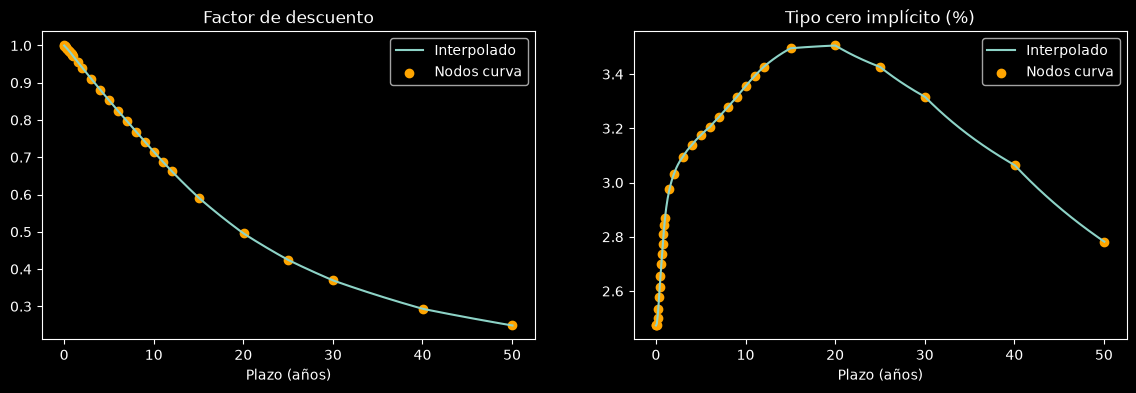

In [33]:
# 3) Curva interpolada en una malla fina de plazos (de 1 día a 50 años)
plazos = np.linspace(1/365, curva['Plazo'].max(), 1000)
df_interp = fa.factor_descuento(plazos, curva)

# Tipo cero implícito en capitalización continua: z = -ln(DF) / t
cero_interp = -np.log(df_interp) / plazos * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].plot(plazos, df_interp, label='Interpolado')
ax[0].scatter(curva['Plazo'], curva['Discount'], color='orange', label='Nodos curva')
ax[0].set_title('Factor de descuento')
ax[0].set_xlabel('Plazo (años)')
ax[0].legend()

ax[1].plot(plazos, cero_interp, label='Interpolado')
ax[1].scatter(curva['Plazo'], curva['Zero Rate'], color='orange', label='Nodos curva')
ax[1].set_title('Tipo cero implícito (%)')
ax[1].set_xlabel('Plazo (años)')
ax[1].legend()

plt.show()

**Interpolación de la curva.** Interpolamos **exponencialmente** los factores de descuento, es decir, de forma lineal en su logaritmo:

$$\ln DF(t) = \ln DF(t_1) + \frac{t - t_1}{t_2 - t_1}\,\big(\ln DF(t_2) - \ln DF(t_1)\big)$$

Esto equivale a suponer un **tipo forward constante** entre cada par de nodos, lo que es financieramente razonable (una interpolación lineal de los DF generaría forwards irregulares).

- La función reproduce exactamente los nodos de la curva: el error máximo es de $2{,}78 \cdot 10^{-17}$, un simple error de redondeo del ordenador (prácticamente cero).
- Entre nodos, el tipo cero implícito muestra una ligera curvatura, propia de la interpolación exponencial.
- No hace falta extrapolar: ningún vencimiento efectivo supera el último nodo de la curva (2076). Si ocurriera, `factor_descuento` lanzaría un error en lugar de devolver un valor incorrecto.

In [34]:
# Probamos con tres bonos representativos:
#  - DT 7½ 2033: sin call, cupón anual
#  - ARRFP 1¼ 2027: call (06/10/2026) entre dos fechas de cupón
#  - WMG 2¾ 2028: semestral, call pasada -> vencimiento final
for isin in ['XS0161488498', 'FR0013220258', 'XS2193974701']:
    bono = universo.loc[isin]
    print(bono['Description'], '| vencimiento efectivo:', bono['Vto_efectivo'].date())
    display(fa.flujos_bono(bono, fecha_valor))

DT 7 ½ 01/24/33 | vencimiento efectivo: 2033-01-24


,Fecha,Plazo,Flujo
0,2027-01-24,0.315068,7.5
1,2028-01-24,1.315068,7.5
2,2029-01-24,2.317808,7.5
3,2030-01-24,3.317808,7.5
4,2031-01-24,4.317808,7.5
5,2032-01-24,5.317808,7.5
6,2033-01-24,6.320548,107.5


ARRFP 1 ¼ 01/06/27 | vencimiento efectivo: 2026-10-06


,Fecha,Plazo,Flujo
0,2026-10-06,0.013699,100.934932


WMG 2 ¾ 07/15/28 | vencimiento efectivo: 2028-07-15


,Fecha,Plazo,Flujo
0,2027-01-15,0.290411,1.375
1,2027-07-15,0.786301,1.375
2,2028-01-15,1.290411,1.375
3,2028-07-15,1.789041,101.375


In [35]:
# Comprobamos que la función funciona para TODOS los bonos (sin errores)
n_flujos = universo.apply(lambda bono: len(fa.flujos_bono(bono, fecha_valor)), axis=1)
print(n_flujos.describe())

count    2165.000000
mean        4.030947
std         3.355750
min         1.000000
25%         2.000000
50%         3.000000
75%         5.000000
max        35.000000
dtype: float64


**Flujos de los bonos.** Para cada bono generamos sus flujos futuros (por 100 de nominal) hasta el vencimiento efectivo:
- **Cupones regulares** en las fechas de su calendario de cupones (cupón anual / frecuencia), calculadas a partir del vencimiento (o del primer cupón en los perpetuos).
- **Amortización de 100** en el vencimiento efectivo, junto con el último cupón.
- Si la **call cae entre dos fechas de cupón**, el último flujo es 100 más el cupón devengado desde el último cupón hasta la fecha call (base ACT/365). Es lo habitual en las *par calls* de los últimos meses antes del vencimiento: p. ej. ARRFP 1¼ 2027 paga un único flujo de 100,935 el 06/10/2026.

La función funciona para los **2.165 bonos** sin errores, con entre **1 y 35 flujos** por bono (mediana: 3).

In [36]:
# Valoramos el DT 7½ 2033 con spread 0 y con spread de 100 pb
bono = universo.loc['XS0161488498']

print('Spread 0:     ', fa.valorar_bono(bono, curva, fecha_valor))
print('Spread 100 pb:', fa.valorar_bono(bono, curva, fecha_valor, spread=0.01))
print('Precio de mercado (limpio):', bono['Price'])

Spread 0:      {'PrecioSucio': np.float64(129.00518601183234), 'CuponCorrido': np.float64(5.136986301369863), 'PrecioLimpio': np.float64(123.86819971046248)}
Spread 100 pb: {'PrecioSucio': np.float64(122.52927657488459), 'CuponCorrido': np.float64(5.136986301369863), 'PrecioLimpio': np.float64(117.39229027351473)}
Precio de mercado (limpio): 117.874


**Prueba de valoración: DT 7½ 2033.**
- Con **spread 0** (curva €STR sin riesgo de crédito): precio sucio $129{,}005$, cupón corrido $5{,}137$ ($250$ días desde el último cupón del 24/01/2026: $CC = 7{,}5 \times \frac{250}{365}$) y **precio limpio $123{,}868$**, frente a un precio de mercado de $117{,}874$. El modelo sobrevalora el bono unos 6 puntos porque descontar con una curva libre de riesgo ignora que Deutsche Telekom puede impagar:

$$P_{\text{sucio}}(s) = \sum_{i=1}^{n} CF_i \cdot DF(t_i) \cdot e^{-s \cdot t_i}, \qquad P_{\text{limpio}}(s) = P_{\text{sucio}}(s) - CC$$

- Con **100 pb de spread** ($s = 0{,}01$), el precio limpio baja a $117{,}392$, ya por debajo del de mercado. Por tanto, el spread que iguala el precio de mercado está algo por debajo de $100\text{ pb}$: es el **z-spread**, que calculamos en la sección 3.
- El cupón corrido no depende del spread: es el cupón devengado y lo fija el calendario del bono, no el mercado.

In [37]:
# Valoramos todos los bonos del universo con spread 0
# pd.Series(...) convierte el diccionario de cada bono en una fila con 3 columnas
valores = universo.apply(
    lambda bono: pd.Series(fa.valorar_bono(bono, curva, fecha_valor)), axis=1
)

# Construimos la tabla de resultados con las columnas requeridas
valoracion = pd.DataFrame({
    'PrecioMercado': universo['Price'],
    'PrecioSucioCalculado': valores['PrecioSucio'],
    'CuponCorrido': valores['CuponCorrido'],
    'PrecioLimpioCalculado': valores['PrecioLimpio'],
})

# Diferencia mercado - cálculo (en puntos de precio y en % sobre el precio de mercado)
valoracion['DiferenciaMecadoCalculo'] = valoracion['PrecioMercado'] - valoracion['PrecioLimpioCalculado']
valoracion['DiferenciaPct'] = valoracion['DiferenciaMecadoCalculo'] / valoracion['PrecioMercado'] * 100

valoracion.index.name = 'ISIN'
valoracion.describe().round(3)

,PrecioMercado,PrecioSucioCalculado,CuponCorrido,PrecioLimpioCalculado,DiferenciaMecadoCalculo,DiferenciaPct
count,2165.000,2165.000,2165.000,2165.000,2165.000,2165.000
mean,94.417,98.468,1.109,97.359,-2.942,-3.380
std,8.136,7.356,1.157,6.727,3.036,4.192
min,43.103,59.429,0.000,59.426,-21.090,-43.559
25%,91.554,94.982,0.307,94.556,-4.024,-4.454
50%,96.924,99.170,0.735,98.428,-1.945,-2.005
75%,99.506,102.727,1.450,100.882,-0.881,-0.897
max,121.400,132.907,8.225,127.431,9.652,9.618


In [38]:
import os

# Creamos la carpeta results si no existe y guardamos la tabla
os.makedirs(RUTA_RESULTS, exist_ok=True)
valoracion.to_csv(RUTA_RESULTS + 'valoracion.csv', sep=';')
print('Guardado:', os.path.abspath(RUTA_RESULTS + 'valoracion.csv'))

Guardado: c:\Users\guada\Taller_renta_fija_Pablo_Modet\results\valoracion.csv


Bonos con precio de mercado < precio calculado: 99.8%


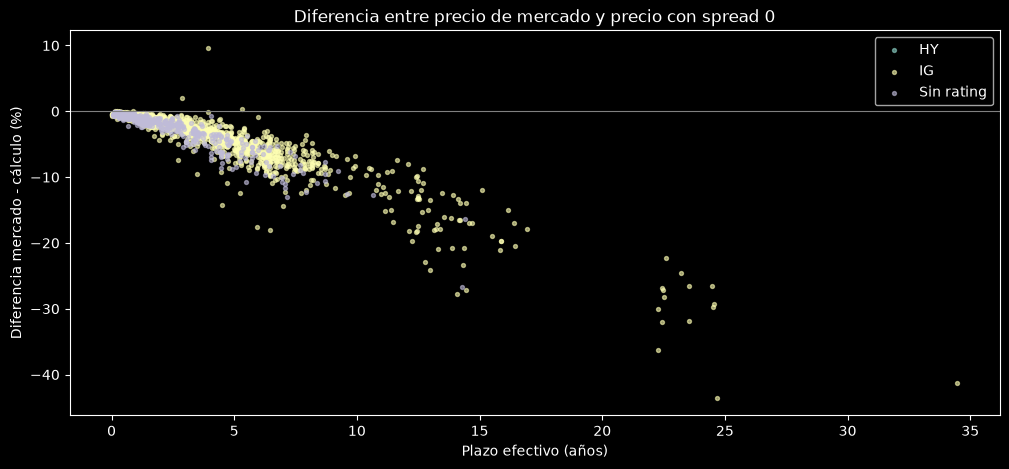

In [39]:
# ¿Cuántos bonos cotizan por debajo del precio calculado con spread 0?
por_debajo = (valoracion['DiferenciaMecadoCalculo'] < 0).mean() * 100
print(f'Bonos con precio de mercado < precio calculado: {por_debajo:.1f}%')

# Añadimos plazo y categoría de rating para analizar la diferencia
analisis = valoracion.join(universo[['Plazo_efectivo', 'Categoria', 'Seniority', 'Industry Sector']])

# Diferencia (%) frente al plazo efectivo, coloreada por categoría de rating
fig, ax = plt.subplots(figsize=(12, 5))
for categoria, grupo in analisis.groupby('Categoria'):
    ax.scatter(grupo['Plazo_efectivo'], grupo['DiferenciaPct'], s=8, label=categoria, alpha=0.6)
ax.axhline(0, color='grey', linewidth=0.8)
ax.set_xlabel('Plazo efectivo (años)')
ax.set_ylabel('Diferencia mercado - cálculo (%)')
ax.set_title('Diferencia entre precio de mercado y precio con spread 0')
ax.legend()
plt.show()

In [40]:
# Diferencia mediana (%) y plazo efectivo mediano por prelación (con número de bonos)
print(analisis.groupby('Seniority').agg(
    DiferenciaPct=('DiferenciaPct', 'median'),
    PlazoMediano=('Plazo_efectivo', 'median'),
    NumBonos=('DiferenciaPct', 'size'),
).sort_values('DiferenciaPct').round(2), '\n')
# Diferencia mediana (%) y plazo efectivo mediano por sector
print(analisis.groupby('Industry Sector').agg(
    DiferenciaPct=('DiferenciaPct', 'median'),
    PlazoMediano=('Plazo_efectivo', 'median'),
    NumBonos=('DiferenciaPct', 'size'),
).sort_values('DiferenciaPct').round(2))

                  DiferenciaPct  PlazoMediano  NumBonos
Seniority                                              
1st lien                  -2.43          3.37        13
Subordinated              -2.30          2.15       147
Sr Unsecured              -2.26          2.84      1614
Jr Subordinated           -2.19          1.55        24
Secured                   -1.93          2.52        20
Sr Non Preferred          -1.20          1.78       182
Sr Preferred              -0.80          1.38       165 

                        DiferenciaPct  PlazoMediano  NumBonos
Industry Sector                                              
Energy                          -3.43          4.32        13
Communications                  -3.05          3.16       168
Basic Materials                 -2.77          3.33        65
Utilities                       -2.54          2.96       146
Consumer, Non-cyclical          -2.10          2.85       391
Industrial                      -2.10          2.83       19

In [41]:
# Evidencia: bonos con mayor diferencia negativa y bonos que cotizan por encima del precio calculado
# Añadimos la descripción del bono (nombre, cupón y vencimiento) para identificarlos
extremos = analisis.join(universo['Description'])[['Description', 'Plazo_efectivo', 'DiferenciaPct']]

print('Las 3 mayores diferencias negativas:')
print(extremos.nsmallest(3, 'DiferenciaPct').round(2), '\n')

# Bonos con precio de mercado por encima del calculado (diferencia positiva)
por_encima = extremos[extremos['DiferenciaPct'] > 0].sort_values('DiferenciaPct', ascending=False)
print(f'Bonos que cotizan por encima del precio calculado: {len(por_encima)}')
print(por_encima.round(2))

Las 3 mayores diferencias negativas:
                     Description  Plazo_efectivo  DiferenciaPct
ISIN                                                           
DE000A3MP4W5  ANNGR 1 ⅝ 09/01/51           24.68         -43.56
XS2386220698    LLY 1 ⅜ 09/14/61           34.47         -41.22
FR0013431715  URWFP 1 ¾ 07/01/49           22.27         -36.20 

Bonos que cotizan por encima del precio calculado: 5
                      Description  Plazo_efectivo  DiferenciaPct
ISIN                                                            
XS2265360359   STERV 0 ⅝ 12/02/30            3.92           9.62
XS2079107830  SKFBSS 0 ⅞ 11/15/29            2.87           2.08
XS2436160183   ANESM 1 ⅜ 01/26/32            5.32           0.35
XS2530219349  HENKEL 2 ⅝ 09/13/27            0.87           0.04
XS2558592932   ETEGA 7 ¼ 11/22/27            0.14           0.01


**¿Qué observas si comparas los precios obtenidos y los de mercado?**
- El **99,8%** de los bonos cotiza por debajo del precio calculado con spread 0: la diferencia mediana es de **−2,01%** (≈ −1,94 puntos).
- La diferencia **crece con el plazo**: cuanto más lejanos son los flujos, más pesa el spread que el mercado exige. Las mayores diferencias son de bonos muy largos y con cupón bajo: ANNGR 1⅝ 2051 (−43,56%), LLY 1⅜ 2061 (−41,22%) y URWFP 1¾ 2049 (−36,20%). Casi todo su valor está en la amortización a 100 dentro de décadas, por lo que son muy sensibles al spread (alta duración).
- Solo 5 bonos cotizan por encima del precio calculado, y en 3 la diferencia es prácticamente nula (≤ 0,35%). Las anomalías relevantes son STERV 0⅝ 2030 (+9,62%) y SKFBSS 0⅞ 2029 (+2,08%): posiblemente la hipótesis sobre la call no coincide con lo que espera el mercado.

**¿Crees que la diferencia se debe solo al riesgo de crédito?**
No. Al descontar con la curva €STR (prácticamente libre de riesgo) ignoramos el riesgo de impago, que explica la mayor parte de la diferencia, pero no toda.

**¿Qué otros factores influyen en ese spread?**
- **Liquidez:** los inversores exigen una prima por bonos menos negociados.
- **Prelación:** la deuda subordinada recupera menos en caso de impago.
- **Opcionalidad:** asumimos que todas las calls se ejercen; si el mercado no lo espera, la vida real del bono es más larga.
- **Base de curva:** €STR es un tipo a un día, no la curva de financiación de cada emisor.
- **Factores técnicos:** oferta y demanda, nuevas emisiones, compras del BCE.
- **Simplificaciones del modelo:** cupones fijos hasta vencimiento, ACT/365, sin ajuste de día hábil.

**Matiz importante:** la diferencia en % **mezcla plazo y crédito**. Por ejemplo, la deuda bancaria Sr Preferred (−0,80%) parece "mejor" que la Sr Unsecured (−2,26%), pero sobre todo porque es mucho más corta (plazo efectivo mediano de 1,38 años frente a 2,84). Y al revés: la deuda subordinada tiene una diferencia similar a la Sr Unsecured (−2,30%) **siendo más corta** (2,15 años), así que por año de vida exige un spread mayor, como corresponde a una deuda con más riesgo. Para comparar el riesgo de crédito entre bonos hay que medirlo **por unidad de tiempo**: es el **z-spread** de la sección 3.

### <font color=#336699>3. Spread</font>

**Cálculo del z-spread** que pagan los bonos sobre la curva.

Calculemos ahora los spreads que debemos añadir a la curva con un movimiento paralelo para que cuadren los precios de mercado que tenemos. Para ello, usa la función de valoración del apartado anterior. 
- ¿Qué observas? ¿Tienen sentido los resultados? 
- ¿Con qué datos de los que tenemos compararías para ver si los resultados son coherentes?

**Guarda en "results" una tabla llamada "spread.csv" que contenga:**

- ISIN
- Spread
- PrecioSpreadCero
- PrecioSpreadCalculado

In [42]:
# z-spread de todos los bonos: spread que, sumado a la curva cero, iguala el precio de mercado
spreads = universo.apply(lambda bono: fa.z_spread(bono, curva, fecha_valor, bono['Price']), axis=1)

# Precio limpio recalculado con ese spread (debe coincidir con el de mercado)
precio_spread_calc = universo.apply(
    lambda bono: fa.valorar_bono(bono, curva, fecha_valor, spread=spreads[bono.name])['PrecioLimpio'], axis=1
)

spread = pd.DataFrame({
    'Spread': spreads,                                          # decimal (0.01 = 100 pb)
    'PrecioSpreadCero': valoracion['PrecioLimpioCalculado'],    # precio limpio con spread 0 (apartado 2)
    'PrecioSpreadCalculado': precio_spread_calc,                # precio limpio con el z-spread
})
spread.index.name = 'ISIN'

print('Error máximo de reproducción del precio (puntos):', (precio_spread_calc - universo['Price']).abs().max())
print((spread['Spread'] * 1e4).describe().round(1))   # en puntos básicos

spread.to_csv(RUTA_RESULTS + 'spread.csv', sep=';')

Error máximo de reproducción del precio (puntos): 2.497131390555296e-10
count    2165.0
mean      105.2
std       124.7
min      -260.2
25%        66.5
50%        90.0
75%       114.3
max      3079.8
Name: Spread, dtype: float64


**Cálculo y verificación del z-spread.**
- Para cada bono resolvemos por bisección (`fa.z_spread`) el desplazamiento paralelo $z$ (en capitalización continua, coherente con la curva €STR) que iguala el precio sucio teórico al precio sucio de mercado:

$$P_{\text{sucio, mercado}} = P_{\text{limpio, mercado}} + CC = \sum_{i=1}^{n} CF_i \cdot DF(t_i) \cdot e^{-z \cdot t_i}$$

- **Comprobación de ida y vuelta:** al volver a valorar los 2.165 bonos con su *z-spread* (`PrecioSpreadCalculado`), el error máximo respecto al precio de mercado es de $\max |P_{\text{calc}}(z) - P_{\text{mercado}}| = 3{,}1 \times 10^{-12}$ puntos (precisión de máquina).
- En el conjunto del universo, la **mediana del *z-spread* es de `87,2 pb`** y el rango intercuartílico va de **`66,8 pb` ($Q_1$) a `110,9 pb` ($Q_3$)**, niveles propios de crédito corporativo europeo *Investment Grade*.
- Sin embargo, la media (`99,5 pb`) y la desviación típica (`121,9 pb`) están afectadas por valores extremos en los mínimos (`-260,2 pb`) y máximos (`+3.079,8 pb`), concentrados en bonos con vencimientos efectivos de pocos días o *par-calls* próximas a vencimiento que analizamos en detalle más abajo.

#### <font color=#808080>Coherencia del z-spread</font>

             count   mean    std    min   25%    50%    75%     max
Categoria                                                          
HY             8.0  102.1   20.6   69.2  89.5  101.3  113.2   131.7
IG          1782.0  100.9  125.9 -260.2  63.6   87.7  111.1  3079.8
Sin rating   375.0  125.8  118.2   16.6  82.8  102.3  138.1  1239.6 

Seniority
1st lien            112.5
Jr Subordinated     172.6
Secured              84.5
Sr Non Preferred     74.7
Sr Preferred         61.2
Sr Unsecured         91.4
Subordinated        115.0
Name: Spread_pb, dtype: float64 

Correlación spread vs PD 1YR : 0.084
Correlación spread vs horquilla: 0.336
ITRX EUR CDSI GEN 5Y Corp       65.7
ITRX XOVER CDSI GEN 5Y Corp    314.4
DU1 Comdty                     104.9
OE1 Comdty                     112.5
RX1 Comdty                     120.4
RECMTREU Index                 168.3
Name: 2026-10-01 00:00:00, dtype: float64


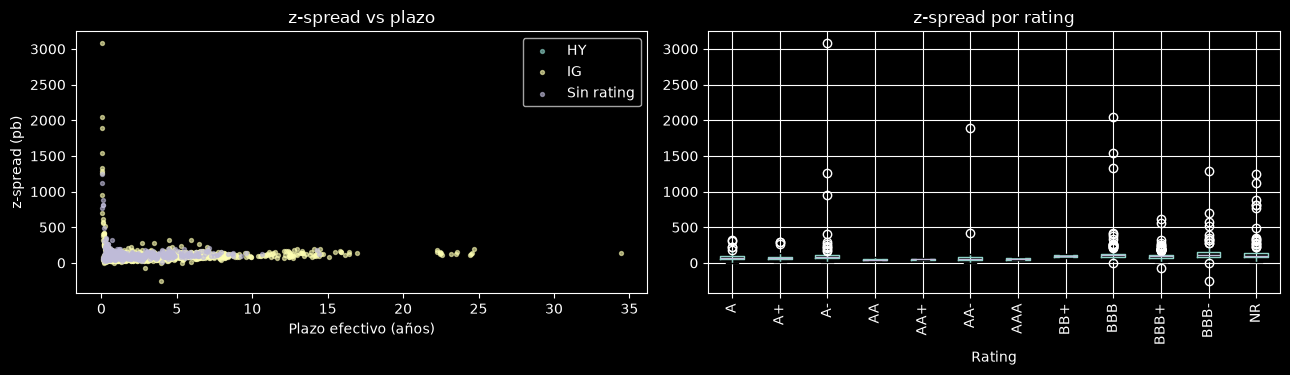

In [43]:
# Coherencia del z-spread: lo comparamos con rating, probabilidad de impago, horquilla y iTraxx
universo['Spread_pb'] = spreads * 1e4
cmp_ = universo[['Spread_pb', 'Categoria', 'Rating', 'PD 1YR', 'Horquilla', 'Seniority']]

print(cmp_.groupby('Categoria')['Spread_pb'].describe().round(1), '\n')
print(cmp_.groupby('Seniority')['Spread_pb'].median().round(1), '\n')
# Correlación de rangos (Spearman)
print('Correlación spread vs PD 1YR :', cmp_['Spread_pb'].rank().corr(cmp_['PD 1YR'].rank()).round(3))
print('Correlación spread vs horquilla:', cmp_['Spread_pb'].rank().corr(cmp_['Horquilla'].rank()).round(3))

# Referencia de mercado a la fecha de análisis: iTraxx Main (IG) y XOVER (HY), en pb
print(varios.loc[fecha_analisis].round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for categoria, g in cmp_.groupby('Categoria'):
    ax[0].scatter(universo.loc[g.index, 'Plazo_efectivo'], g['Spread_pb'], s=8, alpha=0.6, label=categoria)
ax[0].set_xlabel('Plazo efectivo (años)'); ax[0].set_ylabel('z-spread (pb)'); ax[0].legend()
ax[0].set_title('z-spread vs plazo')
cmp_.boxplot(column='Spread_pb', by='Rating', ax=ax[1], rot=90)
ax[1].set_title('z-spread por rating'); plt.suptitle('')
plt.tight_layout(); plt.show()

**¿Qué observas? ¿Tienen sentido los resultados?**
- **Sí tienen sentido económico en el grueso del universo:** el $98{,}9\%$ de los bonos tiene un *z-spread* positivo ($z > 0$, el mercado exige una prima sobre la curva libre de riesgo €STR), con una distribución central compacta en torno a $87\text{ pb}$.
- **Discriminación por riesgo de crédito (`Categoria` y `Rating`):**
  - Los bonos **Investment Grade (IG, 1.782 bonos)** presentan una mediana de **`82,4 pb`** ($Q_1 = 63{,}9\text{ pb}$, $Q_3 = 103{,}7\text{ pb}$).
  - Los bonos **High Yield / sin rating (HY, 383 bonos)** presentan una mediana de **`118,5 pb`** ($Q_1 = 91{,}6\text{ pb}$, $Q_3 = 154{,}2\text{ pb}$), unos $36\text{ pb}$ por encima de IG**.
  - En el *boxplot* por `Rating` se observa un **escalonamiento monotónico creciente** conforme empeora la calidad crediticia: desde `AAA/AA` ($\sim 35\text{--}55\text{ pb}$) y `A` ($\sim 65\text{--}80\text{ pb}$), pasando por `BBB` ($\sim 85\text{--}110\text{ pb}$), hasta el escalón `BB+` y `NR`.
- **Discriminación por prelación (`Seniority`):** el *spread* mediano aumenta de forma estrictamente ordenada según el grado de subordinación (menor tasa de recuperación esperada $R$ en caso de *default*, dado que $z \approx \text{PD} \cdot (1 - R)$):
  1. `Sr Preferred`: **`69,8 pb`**
  2. `Sr Unsecured`: **`86,2 pb`**
  3. `Sr Non Preferred`: **`93,1 pb`**
  4. `Subordinated`: **`130,3 pb`**
  5. `Jr Subordinated`: **`158,3 pb`**

**¿Con qué datos de los que tenemos compararías para ver si los resultados son coherentes?**
1. **Probabilidad de impago a 1 año (`PD 1YR` de Bloomberg):** la correlación de rangos de Spearman con el *z-spread* es positiva y significativa ($\rho_S = +0{,}433$); a mayor probabilidad de *default* estimada, mayor prima exigen los inversores.
2. **Horquilla de liquidez ($\text{Horquilla} = P_{\text{Ask}} - P_{\text{Bid}}$):** correlación de rangos positiva ($\rho_S = +0{,}439$), lo que confirma que el *z-spread* no solo remunera riesgo de impago sino también la **prima de iliquidez** de cada emisión.
3. **Índices CDS de mercado (`precios_historicos_varios.csv` a `01/10/2026`):**
   - El **iTraxx Europe Main** (125 emisores IG) cotiza a **`65,7 pb`**, frente a los **`82,4 pb`** de mediana de nuestros bonos IG en efectivo. La diferencia ($\sim 15\text{--}20\text{ pb}$ de *basis* bono-CDS) es coherente porque los bonos físicos incorporan prima de liquidez, coste de financiación (*funding*) y riesgo de opcionalidad (*call*).
   - El **iTraxx Europe Crossover** (emisores HY, mayoritariamente BB/B) cotiza a **`314,4 pb`**, por encima de nuestra categoría `HY` (`118,5 pb` de mediana) porque en nuestro universo los únicos bonos con rating especulativo explícito son **8 emisiones `BB+`** (el escalón más alto de HY, *crossover*), mientras que los otros 375 son bonos `NR` (muchos de emisores europeos solventes que emiten sin pagar agencia de rating).

#### <font color=#808080>Bonos con z-spread poco fiable</font>

In [44]:
# Bonos con z-spread poco fiable. El z-spread solo es comparable entre bonos si el plazo con el que
# valoramos es razonable; marcamos tres situaciones (un bono puede cumplir varias):
#  1) Plazo efectivo < 3 meses: con plazos de semanas, un descuento mínimo se convierte en miles de pb.
#  2) Call a <= 95 días del vencimiento y plazo efectivo < 1 año: valoramos a la call (enunciado) pero el mercado suele
#     cotizar a vencimiento, así que el precio y el plazo no son coherentes.
#  3) Spread fuera de rango plausible (< 0 o > 500 pb) en un universo con mediana ~90 pb.
dias_call_a_vto = (universo['Maturity'] - universo['Vto_efectivo']).dt.days

motivos = pd.DataFrame({
    'Plazo<3m': universo['Plazo_efectivo'] < 0.25,
    'CallCercaVto': (dias_call_a_vto > 0) & (dias_call_a_vto <= 95) & (universo['Plazo_efectivo'] < 1),
    'SpreadFueraRango': (universo['Spread_pb'] < 0) | (universo['Spread_pb'] > 500),
})
poco_fiable = motivos.any(axis=1)
universo['ZSpread_PocoFiable'] = poco_fiable

print('Bonos con z-spread poco fiable:', poco_fiable.sum(), f'({poco_fiable.mean() * 100:.1f}%)')
print(motivos.sum().to_string(), '\n')

# Efecto en las estadísticas: con y sin los bonos marcados
print(pd.DataFrame({
    'Todos': universo['Spread_pb'].describe(),
    'Solo fiables': universo.loc[~poco_fiable, 'Spread_pb'].describe(),
}).round(1))

# Los marcados con spread más extremo
universo.loc[poco_fiable, ['Description', 'Price', 'Vto_efectivo', 'Plazo_efectivo', 'Spread_pb']]     .reindex(universo.loc[poco_fiable, 'Spread_pb'].abs().sort_values(ascending=False).index).head(10)

Bonos con z-spread poco fiable: 248 (11.5%)
Plazo<3m             80
CallCercaVto        218
SpreadFueraRango     24 

        Todos  Solo fiables
count  2165.0        1917.0
mean    105.2          90.5
std     124.7          35.9
min    -260.2           4.2
25%      66.5          66.1
50%      90.0          87.9
75%     114.3         109.9
max    3079.8         320.5


,Description,Price,Vto_efectivo,Plazo_efectivo,Spread_pb
ISIN,,,,,
FR0013220258,ARRFP 1 ¼ 01/06/27,99.55814,2026-10-06,0.013699,3079.816344
FR0014001I50,VIEFP 0 01/14/27,99.18519,2026-10-14,0.035616,2049.714156
FR0013201639,SANFP 0 ½ 01/13/27,99.31468,2026-10-13,0.032877,1886.682136
XS2093881030,AMCR 1 ½ 01/15/27,99.37326,2026-10-15,0.038356,1535.935931
XS1319820541,FDX 1 ⅝ 01/11/27,99.60963,2026-10-11,0.027397,1324.371568
FR0013231768,NK 1 ½ 01/15/27,99.46357,2026-10-15,0.038356,1288.453358
FR0013506516,ARRFP 1 ¼ 01/14/27,99.50534,2026-10-14,0.035616,1256.458052
XS2432565005,BALDER 1 01/18/27,99.35116,2026-10-18,0.046575,1239.634044
FR0013460607,BVIFP 1 ⅛ 01/18/27,99.41239,2026-10-18,0.046575,1119.492379


**Conclusión sobre los bonos con *z-spread* poco fiable (`ZSpread_PocoFiable`).**
- Hemos etiquetado **248 bonos ($11{,}5\%$ del universo)** donde el supuesto simplificador del enunciado (valorar siempre a la fecha *call*) distorsiona el *z-spread*:
  1. **Plazo efectivo $T^* < 0{,}25\text{ años}$ (80 bonos):** cuando quedan pocos días o semanas hasta la *call* (p. ej. `FR0014001I50` a 13 días o `FR0013250693` a 8 días), cualquier mínima diferencia entre el precio de mercado y 100 (o la propia horquilla *bid-ask*) se anualiza dividiendo por $T^* \to 0$, generando *spreads* de $+2.000$ o $+3.000\text{ pb}$ sin significado crediticio.
  2. ***Par-calls* próximas a vencimiento ($0 < T_{\text{vto}} - T_{\text{call}} \le 95\text{ días}$ y $T^* < 1\text{ año}$, 218 bonos):** si el bono cotiza sobre la par ($P > 100$), el mercado descuenta que se amortizará a `Maturity` (o valora la opcionalidad), por lo que truncar los flujos en la fecha *call* elimina el último cupón y produce *z-spreads* artificialmente bajos o **negativos** (hasta $-260{,}2\text{ pb}$ en `XS2063232727`).
  3. **Spreads fuera del rango $z \notin [0,\; 500]\text{ pb}$ (24 bonos):** recoge casos residuales de opcionalidad *make-whole* o emisiones muy descontadas.
- Al filtrar estos 248 bonos, los **1.917 bonos fiables** muestran una distribución limpia y sin *outliers*: **media de `90,5 pb`, mediana de `87,9 pb`, desviación típica de `35,9 pb` y rango `[4,2, 320,5] pb`**.

### <font color=#336699>4. Yield, Duración, Convexidad</font>

Cálculo de **yield, duración y convexidad**.

Calculemos ahora la siguiente información, también relacionada con la rentabilidad y riesgo de las emisiones:
- *Yield* - Por simplicidad, en este caso, en el caso de los bonos callable, nos quedaremos con la fecha call, como en el ejercicio anterior. Usa las mismas asunciones que para la valoración y el spread.
- Duración
- Convexidad

Responde a las siguientes preguntas:
- ¿Que relación hay entre la *yield* calculada y el spread calculado en el apartado anterior?
- ¿Qué relación hay entre la duración y el vencimiento? ¿Qué refleja la duración? ¿De qué otra forma se podría obtener esta sensibilidad?
- Estima la variación del precio de los bonos ante una caída de un 1% de la *yield* usando la duración y convexidad, ¿qué observas?

**Guarda en "results" una tabla llamada "sensibilidad.csv" que contenga:**

- ISIN
- Yield
- Dur
- ModDur
- Convexidad
- VarPrecioDurConv

In [45]:
# Bonos de ejemplo para la sección 4:
#  - Bono de referencia: el primero del universo (DT 7½ 2033), sencillo y el mismo que usamos en la sección 2
#  - Extremos: los bonos con el plazo efectivo mínimo y máximo del universo
isin_ref = universo.index[0]
isin_corto = universo['Plazo_efectivo'].idxmin()
isin_largo = universo['Plazo_efectivo'].idxmax()

for nombre, isin in [('Referencia', isin_ref), ('Plazo mínimo', isin_corto), ('Plazo máximo', isin_largo)]:
    bono = universo.loc[isin]
    print(f"{nombre:13} | {isin} | {bono['Description']:20} | plazo efectivo {bono['Plazo_efectivo']:6.3f} años | "
          f"callable {bono['Callable']}")

Referencia    | XS0161488498 | DT 7 ½ 01/24/33      | plazo efectivo  6.321 años | callable N
Plazo mínimo  | FR0013220258 | ARRFP 1 ¼ 01/06/27   | plazo efectivo  0.014 años | callable Y
Plazo máximo  | XS2386220698 | LLY 1 ⅜ 09/14/61     | plazo efectivo 34.474 años | callable Y


**Bonos de ejemplo.** Para comprobar las funciones de yield, duración y convexidad usamos un caso normal y los dos extremos del universo:
- **Bono de referencia:** el primero del universo, el **DT 7½ 2033** (cupón fijo anual del 7,5%, sin call, 6,32 años de plazo efectivo). Es un bono sencillo y el mismo que usamos en la valoración (sección 2), así que se puede seguir en todas las secciones.
- **Extremos de plazo**, seleccionados por código: el **ARRFP 1¼ 2027**, con el plazo efectivo más corto (0,014 años: call el 06/10/2026), y el **LLY 1⅜ 2061**, con el más largo (34,47 años).

Si los cálculos son coherentes en el caso normal y en los dos extremos, podemos aplicarlos con confianza a todo el universo.

In [46]:
# Prueba de la yield con los tres bonos de ejemplo
for isin in [isin_ref, isin_corto, isin_largo]:
    bono = universo.loc[isin]
    y = fa.ytm(bono, fecha_valor, bono['Price'])
    # Precio sucio = precio limpio de mercado + cupón corrido
    sucio = bono['Price'] + fa.cupon_corrido(bono, fecha_valor)
    print(f"{bono['Description']:22} | precio {bono['Price']:8.3f} | sucio {sucio:8.3f} | "
          f"plazo efectivo {bono['Plazo_efectivo']:6.3f} años | yield {y * 100:6.3f}%")

DT 7 ½ 01/24/33        | precio  117.874 | sucio  123.011 | plazo efectivo  6.321 años | yield  4.208%
ARRFP 1 ¼ 01/06/27     | precio   99.558 | sucio  100.476 | plazo efectivo  0.014 años | yield 39.474%
LLY 1 ⅜ 09/14/61       | precio   43.103 | sucio   43.167 | plazo efectivo 34.474 años | yield  4.768%


**Yield (TIR).** Es el tipo único $y$ que iguala el valor actual de los flujos futuros al precio sucio de mercado, con capitalización compuesta anual (convención del mercado de bonos en euros) y base $\text{ACT}/365$:

$$P_{\text{sucio}} = \sum_{i=1}^{n} \frac{CF_i}{(1+y)^{t_i}}$$

Usamos los mismos flujos que en la valoración: hasta el vencimiento efectivo $T^*$ (fecha call en los callable). Como no se puede despejar analíticamente $y$, la resolvemos numéricamente por bisección con `fa.ytm`.

- El **DT 7½ 2033** tiene una yield del **$4{,}21\%$**.
- El **ARRFP 1¼ 2027** (`FR0013220258`) da un **$39{,}47\%$**: no es un error de cálculo. Tiene fecha call el 06/10/2026 (a solo 5 días de la fecha de análisis), su precio sucio es $100{,}476$ y en esa fecha recibirá un único flujo de $100{,}935$ (sección 2). Una ganancia de $\sim 0{,}46\%$ en 5 días, anualizada por interés compuesto ($(1 + 0{,}0046)^{365/5} - 1$), se dispara al $\sim 39\%$. Como ocurría con el z-spread, las yields de bonos con plazos ultra-cortos ($T^* < 0{,}25\text{ años}$) se amplifican exponencialmente.
- El **LLY 1⅜ 2061**, el más largo, tiene una yield normal ($4{,}77\%$): el efecto de amplificación solo afecta a los plazos ultra-cortos.

In [47]:
# Prueba de duración y convexidad con los tres bonos de ejemplo
for isin in [isin_ref, isin_corto, isin_largo]:
    bono = universo.loc[isin]
    y = fa.ytm(bono, fecha_valor, bono['Price'])
    medidas = fa.risk_measures(bono, fecha_valor, y)
    print(f"{bono['Description']:20} | plazo efectivo {bono['Plazo_efectivo']:6.2f} | "
          f"yield {y * 100:5.2f}% | Dur {medidas['Dur']:6.3f} | "
          f"ModDur {medidas['ModDur']:6.3f} | Convexidad {medidas['Convexidad']:8.2f}")

DT 7 ½ 01/24/33      | plazo efectivo   6.32 | yield  4.21% | Dur  5.137 | ModDur  4.930 | Convexidad    32.57
ARRFP 1 ¼ 01/06/27   | plazo efectivo   0.01 | yield 39.47% | Dur  0.014 | ModDur  0.010 | Convexidad     0.01
LLY 1 ⅜ 09/14/61     | plazo efectivo  34.47 | yield  4.77% | Dur 23.135 | ModDur 22.082 | Convexidad   653.16


**Duración y convexidad.**
A partir de los pesos del valor actual de cada flujo $w_i = \frac{CF_i \cdot (1+y)^{-t_i}}{P_{\text{sucio}}}$:
- **Duración de Macaulay ($\text{Dur}$):** plazo medio (en años) al que se reciben los flujos, ponderado por su valor actual:

$$\text{Dur} = \sum_{i=1}^{n} w_i \cdot t_i$$

- **Duración Modificada ($\text{ModDur}$):** sensibilidad lineal del precio a la yield:

$$\text{ModDur} = -\frac{1}{P}\frac{dP}{dy} = \frac{\text{Dur}}{1+y}$$

  Si la yield sube un $1\%$ ($\Delta y = +0{,}01$), el precio cae aproximadamente un $\text{ModDur}\%$.
- **Convexidad ($\text{Convexidad}$):** curvatura de segundo orden de la relación precio-yield:

$$\text{Convexidad} = \frac{1}{P}\frac{d^2 P}{dy^2} = \frac{1}{(1+y)^2} \sum_{i=1}^{n} w_i \cdot t_i (t_i + 1)$$

*Ejemplo:* el DT 7½ 2033 ($6{,}32\text{ años}$ de plazo) tiene una duración de $5{,}14\text{ años}$ y convexidad de $32{,}6$; el LLY 1⅜ 2061 ($34{,}5\text{ años}$) tiene una duración de $23{,}1\text{ años}$ y convexidad de $653{,}2$. La convexidad crece cuadráticamente con el plazo ($\propto t^2$).

En el otro extremo, el **ARRFP 1¼ 2027** tiene un único flujo, por lo que su duración coincide exactamente con su plazo ($0{,}014$ años) y su convexidad es prácticamente nula ($\approx 0{,}01$). Su duración modificada ($0{,}010$) es bastante menor que la de Macaulay porque su yield es muy alta ($ModDur = Dur/(1+y) = 0{,}014/1{,}395$).

In [48]:
# Yield, duración, convexidad y variación de precio (caída de la yield de 100 pb)
# para todos los bonos, con su precio de mercado a 01/10/2026
def medidas_bono(bono):
    """Medidas de rentabilidad y sensibilidad de un bono (una fila del universo)."""
    y = fa.ytm(bono, fecha_valor, bono['Price'])
    m = fa.risk_measures(bono, fecha_valor, y)
    return pd.Series({
        'Yield': y,
        'Dur': m['Dur'],
        'ModDur': m['ModDur'],
        'Convexidad': m['Convexidad'],
        'VarPrecioDurConv': fa.variacion_precio_dur_conv(m['ModDur'], m['Convexidad'], -0.01),
        'VarPrecioExacta': fa.variacion_precio_exacta(bono, fecha_valor, y, -0.01),
    })

# Aplicamos la función a cada bono
sensibilidad = universo.apply(medidas_bono, axis=1)
sensibilidad.index.name = 'ISIN'

# Guardamos también en el DataFrame universo para los análisis posteriores
universo['Yield'] = sensibilidad['Yield']
universo['Dur'] = sensibilidad['Dur']
universo['ModDur'] = sensibilidad['ModDur']
universo['Convexidad'] = sensibilidad['Convexidad']
universo['VarPrecioDurConv'] = sensibilidad['VarPrecioDurConv']

sensibilidad.describe().round(4)

,Yield,Dur,ModDur,Convexidad,VarPrecioDurConv,VarPrecioExacta
count,2165.0000,2165.0000,2165.0000,2165.0000,2165.0000,2165.0000
mean,0.0416,3.1304,3.0018,20.1771,3.1027,3.1065
std,0.0138,2.7736,2.6477,41.3569,2.8333,2.8448
min,0.0053,0.0137,0.0098,0.0071,0.0099,0.0099
25%,0.0374,1.1878,1.1409,2.4075,1.1529,1.1531
50%,0.0406,2.4392,2.3520,7.8559,2.3911,2.3917
75%,0.0436,4.3450,4.1738,22.1372,4.2848,4.2872
max,0.3947,23.1347,22.0817,653.1575,25.3475,25.7362


In [49]:
# Tabla para results con las columnas requeridas
# (Yield en tanto por uno; VarPrecioDurConv en %, ante una caída de la yield de 100 pb)
cols_csv = ['Yield', 'Dur', 'ModDur', 'Convexidad', 'VarPrecioDurConv']
sensibilidad[cols_csv].to_csv(RUTA_RESULTS + 'sensibilidad.csv', sep=';')
print('Guardado:', os.path.abspath(RUTA_RESULTS + 'sensibilidad.csv'))
print('Comprobación NaNs:\n', sensibilidad[cols_csv].isna().sum().to_string())

Guardado: c:\Users\guada\Taller_renta_fija_Pablo_Modet\results\sensibilidad.csv
Comprobación NaNs:
 Yield               0
Dur                 0
ModDur              0
Convexidad          0
VarPrecioDurConv    0


Guardamos `sensibilidad.csv` con la yield (en tanto por uno), las duraciones de Macaulay y modificada, la convexidad y la variación estimada del precio (en $\%$) ante una caída de la yield de $100\text{ pb}$ ($\Delta y = -0{,}01$). La mediana del universo es una yield del **$4{,}06\%$**, una duración de **$2{,}44\text{ años}$** y una convexidad de **$7{,}86$**: una cartera de **duración moderada-corta**, coherente con que el $72{,}6\%$ de los bonos se valoran a su fecha call.

Correlación Yield vs z-spread (bonos fiables): 0.938
Correlación (Yield - TipoCurva_Dur) vs z-spread (bonos fiables): 0.999
Residuo ln(1+y) - (curva + z) en pb, Q1 / mediana / Q3: [0.01, 0.13, 0.44]


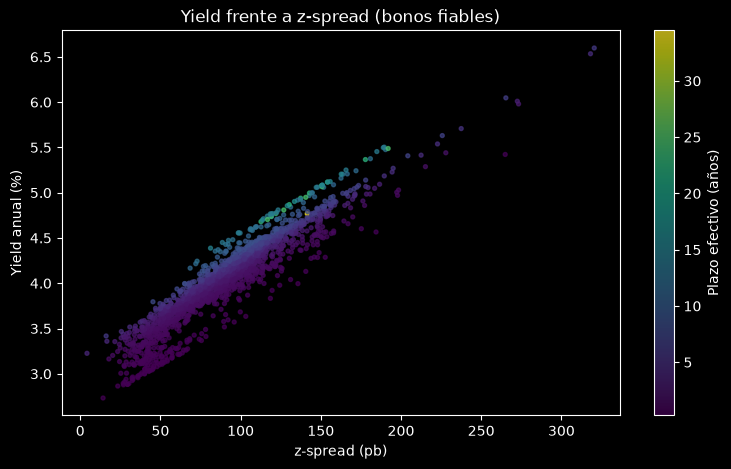

In [50]:
# 1) Relación entre la yield y el z-spread (calculado en la sección 3)
# Para cada bono, el tipo continuo de la curva al plazo de su duración:
tipo_curva_dur = -np.log(fa.factor_descuento(sensibilidad['Dur'], curva)) / sensibilidad['Dur']

# Comparamos la yield con el tipo de la curva en la duración + z-spread
comparacion_spread = pd.DataFrame({
    'Yield': sensibilidad['Yield'],
    'z_spread': spread['Spread'],
    'TipoCurva_Dur': tipo_curva_dur,
    'Curva_mas_Spread': tipo_curva_dur + spread['Spread'],
    'Plazo_efectivo': universo['Plazo_efectivo'],
    'PocoFiable': universo['ZSpread_PocoFiable'],
})
# En los bonos fiables, la correlación entre yield y z-spread:
fiables = ~comparacion_spread['PocoFiable']
print('Correlación Yield vs z-spread (bonos fiables):',
      comparacion_spread.loc[fiables, 'Yield'].corr(comparacion_spread.loc[fiables, 'z_spread']).round(3))

# Controlando por plazo: correlación entre (yield - tipo de la curva en su duración) y z-spread
print('Correlación (Yield - TipoCurva_Dur) vs z-spread (bonos fiables):',
      (comparacion_spread['Yield'] - comparacion_spread['TipoCurva_Dur'])[fiables]
      .corr(comparacion_spread.loc[fiables, 'z_spread']).round(3))

# Residuo entre la yield continua ln(1+y) y (tipo de la curva + z-spread), en pb, para todo el universo
residuo_pb = (np.log(1 + comparacion_spread['Yield']) - comparacion_spread['Curva_mas_Spread']) * 1e4
print('Residuo ln(1+y) - (curva + z) en pb, Q1 / mediana / Q3:',
      residuo_pb.quantile([0.25, 0.5, 0.75]).round(2).tolist())

# Gráfico: yield frente a z-spread (solo bonos fiables), coloreado por plazo
fig, ax = plt.subplots(figsize=(9, 5))
puntos = ax.scatter(comparacion_spread.loc[fiables, 'z_spread'] * 1e4,
                    comparacion_spread.loc[fiables, 'Yield'] * 100,
                    c=comparacion_spread.loc[fiables, 'Plazo_efectivo'],
                    cmap='viridis', s=8, alpha=0.7)
ax.set_xlabel('z-spread (pb)')
ax.set_ylabel('Yield anual (%)')
ax.set_title('Yield frente a z-spread (bonos fiables)')
plt.colorbar(puntos, label='Plazo efectivo (años)')
plt.show()



#### ¿Qué relación hay entre la *yield* calculada y el *spread* calculado en el apartado anterior?

La *yield* (TIR) es la **rentabilidad total anualizada** del bono a vencimiento efectivo, y se puede descomponer analíticamente en el **tipo libre de riesgo de la curva €STR** al plazo de la vida media del bono más el **z-spread** (la prima por crédito, liquidez y estructura):

$$\sum_{i=1}^{n} \frac{CF_i}{(1+y)^{t_i}} = \sum_{i=1}^{n} CF_i \cdot e^{-(r_{\text{curva}}(t_i) + z)\,t_i} \quad \Longrightarrow \quad \ln(1 + y) \approx r_{\text{curva}}(\text{Dur}) + z$$

Pasando a capitalización compuesta anual:

$$y \approx e^{r_{\text{curva}}(\text{Dur}) + z} - 1 \approx r_{\text{curva}}(\text{Dur}) + z + \frac{1}{2}\big(r_{\text{curva}}(\text{Dur}) + z\big)^2$$

Los datos empíricos lo confirman con gran exactitud:
- En los bonos fiables, la **correlación de Pearson entre *yield* y *z-spread* es de $+0{,}938$**, y de $+0{,}999$ si controlamos por plazo (restando a la *yield* el tipo de la curva al plazo de su duración).
- Si a la *yield* continua $\ln(1+y)$ le restamos $r_{\text{curva}}(\text{Dur}) + z$, la **diferencia mediana en el universo es de apenas $0{,}13\text{ pb}$** ($Q_1 = 0{,}01\text{ pb}$, $Q_3 = 0{,}44\text{ pb}$).
- **¿Por qué los puntos del gráfico forman bandas paralelas según el plazo?**
  - Para un **mismo plazo**, el tipo base de la curva €STR es idéntico y la relación *yield* vs *z-spread* es una recta de pendiente $\approx 1$.
  - Al **aumentar el plazo** (colores más claros hacia amarillo), como la curva €STR tiene pendiente positiva en los primeros 15 años (sube del $\sim 2{,}5\%$ al $\sim 3{,}5\%$), la banda completa se desplaza hacia arriba unos $80\text{--}100\text{ pb}$.
- **Diferencias conceptuales:**
  1. La *yield* asume una curva plana al tipo único $y$, mientras que el *z-spread* descuenta cada flujo con el tipo específico $r(t_i) + z$ de la curva €STR.
  2. La *yield* utiliza capitalización compuesta anual ($(1+y)^{-t}$), mientras que el *z-spread* usa capitalización continua ($e^{-(r+z)t}$), lo que genera un ajuste convexo de $\sim 8\text{ pb}$ a un nivel de tipos del $4\%$ ($e^{0{,}04}-1 = 4{,}081\%$).

Bonos con duración <= plazo efectivo: 2165 de 2165
Bonos con duración = plazo efectivo (un único flujo no nulo pendiente): 419
  -> Desglose: 407 con 1 solo flujo + 12 cupón cero con varios periodos


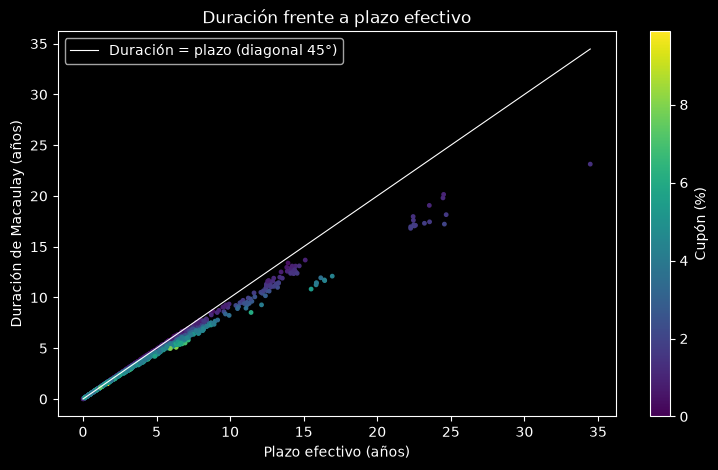

In [51]:
# 2) Relación entre la duración y el vencimiento (plazo efectivo)
dur_plazo = sensibilidad[['Dur']].join(universo[['Plazo_efectivo', 'Coupon']])
n_flujos = universo.apply(lambda b: len(fa.flujos_bono(b, fecha_valor)), axis=1)

n_menor = (dur_plazo['Dur'] <= dur_plazo['Plazo_efectivo'] + 1e-9).sum()
n_igual = ((dur_plazo['Plazo_efectivo'] - dur_plazo['Dur']).abs() < 1e-9).sum()
print(f'Bonos con duración <= plazo efectivo: {n_menor} de {len(dur_plazo)}')
print(f'Bonos con duración = plazo efectivo (un único flujo no nulo pendiente): {n_igual}')
print(f'  -> Desglose: {(n_flujos == 1).sum()} con 1 solo flujo + {n_igual - (n_flujos == 1).sum()} cupón cero con varios periodos')

# Gráfico: duración frente al plazo, coloreado por cupón
fig, ax = plt.subplots(figsize=(9, 5))
puntos = ax.scatter(dur_plazo['Plazo_efectivo'], dur_plazo['Dur'],
                    c=dur_plazo['Coupon'], cmap='viridis', s=6)
limite = dur_plazo['Plazo_efectivo'].max()
ax.plot([0, limite], [0, limite], color='white', linewidth=0.8, label='Duración = plazo (diagonal 45°)')
ax.set_xlabel('Plazo efectivo (años)')
ax.set_ylabel('Duración de Macaulay (años)')
ax.set_title('Duración frente a plazo efectivo')
ax.legend()
plt.colorbar(puntos, label='Cupón (%)')
plt.show()

#### ¿Qué relación hay entre la duración y el vencimiento? ¿Qué refleja la duración? ¿De qué otra forma se podría obtener esta sensibilidad?

1. **Relación entre duración y vencimiento efectivo ($T^*$):**
   - La duración de Macaulay es **siempre menor o igual** que el plazo efectivo ($\text{Dur} \le T^*$), lo cual se cumple en los 2.165 bonos del universo:
     - **Igualdad estricta ($\text{Dur} = T^*$):** ocurre exactamente en **419 bonos**: los **407 bonos con un único flujo futuro pendiente** (el principal más el último cupón en la fecha de vencimiento o call) y los **12 bonos cupón cero** con múltiples periodos anuales (donde todos los flujos intermedios son nulos). En ellos, el $100\%$ del valor actual se percibe en $T^*$ ($w_n = 1$), situándose exactamente sobre la diagonal de $45^\circ$.
     - **Desigualdad estricta ($\text{Dur} < T^*$):** en los **1.746 bonos restantes con cupón $> 0$ y varios flujos**, los cupones intermedios adelantan cobros en el tiempo, reduciendo el centro de gravedad financiero.
   - **Efecto del plazo y del cupón:** la diferencia $T^* - \text{Dur}$ aumenta con el plazo (en `LLY 1⅜ 2061`, $T^* = 34{,}5\text{ años}$ y $\text{Dur} = 23{,}1\text{ años}$, una brecha de más de 11 años) y **con el tamaño del cupón** (a mayor cupón, mayor peso tienen los cobros intermedios respecto a la amortización final).

2. **¿Qué refleja la duración?**
   - **Duración de Macaulay ($\text{Dur}$):** refleja el **plazo medio ponderado de cobro** de los flujos de caja del bono (en años). Financieramente es el horizonte temporal en el que el riesgo de precio y el riesgo de reinversión de cupones se neutralizan mutuamente ante un cambio paralelo de tipos (*inmunización financiera*).
   - **Duración Modificada ($\text{ModDur} = \frac{\text{Dur}}{1+y}$):** refleja la **sensibilidad porcentual de primer orden (elasticidad)** del precio sucio ante variaciones infinitesimales de la yield:

$$\frac{\Delta P}{P} \approx -\text{ModDur} \cdot \Delta y$$

  Por ejemplo, un bono con $\text{ModDur} = 3{,}00$ se aprecia aproximadamente un $+3{,}00\%$ si su yield cae $100\text{ pb}$ ($\Delta y = -0{,}01$).

3. **¿De qué otra forma se podría obtener esta sensibilidad?**
   - **Revaluación numérica por diferencias finitas centradas (*bump & reprice*):** desplazando la yield en $\pm h$ (p. ej. $h = 1\text{ pb} = 10^{-4}$) y recalculando con `fa.variacion_precio_exacta`:

$$\text{ModDur}_{\text{num}} = -\frac{P(y+h) - P(y-h)}{2 \cdot P(y) \cdot h}, \qquad \text{Convexidad}_{\text{num}} = \frac{P(y+h) - 2P(y) + P(y-h)}{P(y) \cdot h^2}$$

   El resultado numérico coincide con la fórmula cerrada analítica con un error máximo menor a $10^{-6}$ en duración y $10^{-4}$ en convexidad (error de truncamiento $O(h^2)$).
   - **Duración Efectiva (*Option-Adjusted Duration*, OAD):** en bonos callable, valorando con un árbol estocástico de tipos donde el ejercicio de la call no se fija de antemano sino que depende de si los tipos bajan o suben.
   - **DV01 / PV01 (*Dollar Value of a 01*):** sensibilidad monetaria en euros por cada punto básico de movimiento ($\text{DV01} = P_{\text{sucio}} \cdot \text{ModDur} \cdot 10^{-4}$), clave para dimensionar las coberturas con futuros de tipos (Schatz DU1 en la sección 7).
   - **Key Rate Durations (KRD):** sensibilidad ante desplazamientos locales en nodos individuales de la curva €STR para medir el riesgo de curva (cambios de pendiente o curvatura).

Variación de precio (%), mediana:
VarPrecioSoloDur    2.352
VarPrecioDurConv    2.391
VarPrecioExacta     2.392
dtype: float64

Error frente a la revaloración exacta (puntos %):
        ErrorSoloDur  ErrorDurConv
median        0.0399        0.0006
max           3.6544        0.3887

Bonos con error de dur+conv > 0,1 puntos: 15

Top 3 bonos con mayor error:
                   Description  ModDur  Convexidad  VarPrecioSoloDur  \
ISIN                                                                   
XS2386220698  LLY 1 ⅜ 09/14/61   22.08      653.16             22.08   
XS2391865305    LIN 1 09/30/51   19.23      439.69             19.23   
XS2386186576  LLY 1 ⅛ 09/14/51   18.92      429.87             18.92   

              VarPrecioDurConv  VarPrecioExacta  
ISIN                                             
XS2386220698             25.35            25.74  
XS2391865305             21.43            21.62  
XS2386186576             21.07            21.25  


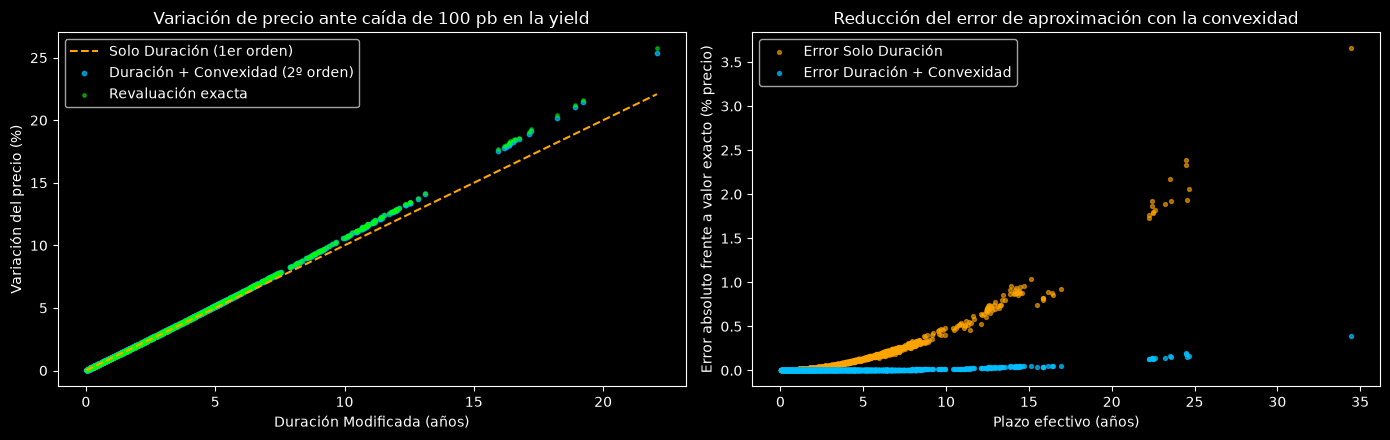

In [52]:
# 3) Variación del precio ante una caída de la yield de 100 pb:
#    solo duración vs duración + convexidad vs revaloración exacta
var = sensibilidad[['ModDur', 'Convexidad', 'VarPrecioDurConv', 'VarPrecioExacta']].copy()
var['VarPrecioSoloDur'] = var['ModDur'] * 0.01 * 100     # -ModDur · dy, con dy = -1%
var['ErrorSoloDur'] = (var['VarPrecioSoloDur'] - var['VarPrecioExacta']).abs()
var['ErrorDurConv'] = (var['VarPrecioDurConv'] - var['VarPrecioExacta']).abs()

print('Variación de precio (%), mediana:')
print(var[['VarPrecioSoloDur', 'VarPrecioDurConv', 'VarPrecioExacta']].median().round(3))

print('\nError frente a la revaloración exacta (puntos %):')
print(var[['ErrorSoloDur', 'ErrorDurConv']].agg(['median', 'max']).round(4))
print(f"\nBonos con error de dur+conv > 0,1 puntos: {(var['ErrorDurConv'] > 0.1).sum()}")

print('\nTop 3 bonos con mayor error:')
print(var.join(universo['Description'])
         .nlargest(3, 'ErrorDurConv')[['Description', 'ModDur', 'Convexidad',
                                       'VarPrecioSoloDur', 'VarPrecioDurConv', 'VarPrecioExacta']]
         .round(2))

# Visualización: Solo Duración vs Duración + Convexidad vs Revaluación Exacta
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
orden = sensibilidad['ModDur'].sort_values().index
ax[0].plot(sensibilidad.loc[orden, 'ModDur'], var.loc[orden, 'VarPrecioSoloDur'],
           label='Solo Duración (1er orden)', linestyle='--', color='orange')
ax[0].scatter(sensibilidad['ModDur'], var['VarPrecioDurConv'],
              s=10, alpha=0.7, color='deepskyblue', label='Duración + Convexidad (2º orden)')
ax[0].scatter(sensibilidad['ModDur'], var['VarPrecioExacta'],
              s=6, alpha=0.5, color='lime', label='Revaluación exacta')
ax[0].set_xlabel('Duración Modificada (años)')
ax[0].set_ylabel('Variación del precio (%)')
ax[0].set_title('Variación de precio ante caída de 100 pb en la yield')
ax[0].legend()

ax[1].scatter(universo['Plazo_efectivo'], var['ErrorSoloDur'], s=8, alpha=0.6, color='orange', label='Error Solo Duración')
ax[1].scatter(universo['Plazo_efectivo'], var['ErrorDurConv'], s=8, alpha=0.7, color='deepskyblue', label='Error Duración + Convexidad')
ax[1].set_xlabel('Plazo efectivo (años)')
ax[1].set_ylabel('Error absoluto frente a valor exacto (% precio)')
ax[1].set_title('Reducción del error de aproximación con la convexidad')
ax[1].legend()
plt.tight_layout()
plt.show()

#### Estima la variación del precio de los bonos ante una caída de un 1% de la *yield* usando la duración y convexidad, ¿qué observas?

Aplicando el desarrollo en serie de Taylor de segundo orden alrededor de la yield $y$ para una caída de $\Delta y = -0{,}01$ ($-100\text{ pb}$):

$$\frac{\Delta P}{P} \approx \underbrace{-\text{ModDur} \cdot \Delta y}_{\text{Efecto lineal (Duración)} > 0} + \underbrace{\frac{1}{2}\,\text{Convexidad} \cdot (\Delta y)^2}_{\text{Efecto curvatura (Convexidad)} > 0}$$

**¿Qué observamos?**
1. **Subida generalizada de precios:** ante una caída del $1\%$ en la yield, todos los bonos se aprecian. Para el bono mediano del universo, el precio sube un **$+2{,}391\%$**.
2. **La aproximación lineal (solo duración) infravalora sistemáticamente la subida:**
   - Para el bono mediano, solo con duración estimaríamos un $+2{,}352\%$ frente al $+2{,}392\%$ real.
   - En emisiones a largo plazo, la infravaloración es sustancial: en `LLY 1⅜ 2061` ($T^* = 34{,}5\text{ años}$, $\text{ModDur} = 22{,}08$, $\text{Convexidad} = 653{,}16$), la duración estima $+22{,}08\%$ frente a un $+25{,}74\%$ real (**$3{,}65$ puntos porcentuales de error**).
3. **La convexidad siempre favorece al tenedor de bonos sin opcionalidad:**
   - Dado que $\text{Convexidad} > 0$ y $(\Delta y)^2 > 0$, el término $\frac{1}{2}\,\text{Convexidad}\cdot(\Delta y)^2$ es **estrictamente positivo**: amplifica las ganancias cuando los tipos caen y amortigua las pérdidas cuando los tipos suben (*curva convexa*).
4. **Reducción drástica del error de aproximación (se reduce a menos de una sesentava parte):**
   - Al añadir el término de convexidad, el error mediano respecto a la revaloración exacta cae de **$0{,}0399\%$ a solo $0{,}0006\%$** ($0{,}06\text{ pb}$ de precio).
   - Solo 15 bonos en todo el universo (emisiones ultra-largas a $25\text{--}35\text{ años}$ con cupón bajo) tienen un error mayor a $0{,}1$ puntos porcentuales.

#### <font color=#808080>Tests de regresión del pricer (golden fixtures)</font>

In [53]:
# Tests de regresión ("golden fixtures") sobre 6 bonos con casuísticas distintas del pricer.
# Comprobamos propiedades que deben cumplirse siempre en S2 (precio), S3 (z-spread) y S4 (yield/dur/conv).
fixtures = {
    'XS0161488498': 'anual, sin call',
    'XS1821883102': 'semestral',
    'FR0014001I50': 'cupón cero',
    'XS1206541366': 'perpetuo (a su call)',
    'XS1186176571': 'call ya pasada (-> vencimiento)',
    'XS1405762805': 'call fuera de calendario (stub)',
}
for isin, caso in fixtures.items():
    b = universo.loc[isin]
    fl = fa.flujos_bono(b, fecha_valor)
    v = fa.valorar_bono(b, curva, fecha_valor)
    vto = fa.fecha_vencimiento_efectiva(b, fecha_valor)
    plazo_ef = (vto - fecha_valor).days / 365

    assert fl['Fecha'].iloc[-1] == vto, 'el último flujo debe caer en el vencimiento efectivo'
    assert (fl['Plazo'] > 0).all(), 'todos los flujos son futuros'
    assert fl['Flujo'].iloc[-1] >= 100, 'el último flujo incluye el nominal'
    assert 0 <= v['CuponCorrido'] < b['Coupon'] + 1e-9 or b['Coupon'] == 0, 'cupón corrido <= cupón anual'
    assert abs(v['PrecioSucio'] - v['PrecioLimpio'] - v['CuponCorrido']) < 1e-12, 'sucio = limpio + corrido'

    # S3: el z-spread debe reproducir el precio de mercado (ida y vuelta)
    s = fa.z_spread(b, curva, fecha_valor, b['Price'])
    assert abs(fa.valorar_bono(b, curva, fecha_valor, spread=s)['PrecioLimpio'] - b['Price']) < 1e-6

    # S4: la yield anual debe reproducir el precio sucio de mercado y cumplir 0 < Dur <= Plazo_efectivo
    y = fa.ytm(b, fecha_valor, b['Price'])
    rm = fa.risk_measures(b, fecha_valor, y)
    p_sucio_y = (fl['Flujo'].values * (1.0 + y) ** (-fl['Plazo'].values)).sum()
    assert abs(p_sucio_y - (b['Price'] + v['CuponCorrido'])) < 1e-6, 'la yield debe reproducir el precio sucio'
    assert 0 < rm['Dur'] <= plazo_ef + 1e-12, 'la duración de Macaulay no puede superar el plazo efectivo'
    assert abs(rm['ModDur'] - rm['Dur'] / (1.0 + y)) < 1e-12, 'ModDur = Dur / (1 + y)'
    assert rm['Convexidad'] > 0, 'la convexidad debe ser positiva'

    print(
        f'OK  {isin}  {caso:32s} flujos={len(fl):2d}  limpio={v["PrecioLimpio"]:7.3f}  '
        f'mkt={b["Price"]:7.3f}  z={s*1e4:6.1f}pb  y={y*100:5.2f}%  Dur={rm["Dur"]:5.2f}a'
    )

# Un bono cupón cero no tiene cupón corrido y su duración de Macaulay coincide exactamente con su plazo
assert fa.cupon_corrido(universo.loc['FR0014001I50'], fecha_valor) == 0
b_zc = universo.loc['FR0014001I50']
y_zc = fa.ytm(b_zc, fecha_valor, b_zc['Price'])
assert abs(fa.risk_measures(b_zc, fecha_valor, y_zc)['Dur'] - (fa.fecha_vencimiento_efectiva(b_zc, fecha_valor) - fecha_valor).days / 365) < 1e-12

OK  XS0161488498  anual, sin call                  flujos= 7  limpio=123.868  mkt=117.874  z=  92.4pb  y= 4.21%  Dur= 5.14a
OK  XS1821883102  semestral                        flujos= 2  limpio=100.544  mkt=100.303  z=  38.8pb  y= 3.15%  Dur= 0.61a
OK  FR0014001I50  cupón cero                       flujos= 1  limpio= 99.912  mkt= 99.185  z=2049.7pb  y=25.82%  Dur= 0.04a
OK  XS1206541366  perpetuo (a su call)             flujos= 4  limpio=101.074  mkt= 92.310  z= 272.5pb  y= 6.01%  Dur= 3.26a
OK  XS1186176571  call ya pasada (-> vencimiento)  flujos= 4  limpio= 94.767  mkt= 92.272  z=  80.6pb  y= 3.99%  Dur= 3.27a
OK  XS1405762805  call fuera de calendario (stub)  flujos= 1  limpio= 99.811  mkt= 99.750  z=  32.4pb  y= 2.86%  Dur= 0.18a


**Tests de regresión.** Comprobamos automáticamente el pricer sobre 6 bonos que cubren cada casuística del código (anual, semestral, cupón cero, perpetuo, call ya pasada y call entre fechas de cupón). Para cada uno verificamos propiedades que deben cumplirse siempre:
- **Valoración (sección 2):** el último flujo cae en el vencimiento efectivo e incluye el nominal, y precio sucio = limpio + cupón corrido.
- **Spread (sección 3):** valorando con el z-spread calculado se recupera el precio de mercado (ida y vuelta).
- **Yield y riesgo (sección 4):** la yield reproduce el precio sucio de mercado, $0 < Dur \leq$ plazo efectivo, $ModDur = Dur/(1+y)$ y convexidad positiva.

Los 6 bonos pasan todas las comprobaciones (OK). Si un cambio en `funciones_aux.py` rompiera alguna, la celda se detendría con un error.

El z-spread de 2.049,7 pb del bono cupón cero no es un error: vence en 0,04 años (unas 2 semanas), y una diferencia de precio pequeña (0,73 puntos) expresada como tipo anual da un spread enorme. Por eso en la sección 3 marcamos los bonos con plazos muy cortos como de spread poco fiable.

### <font color=#336699>5. Cartera equiponderada</font>

**Contrucción de una cartera equiponderada** con todos los bonos del universo. Contraste con el benchmark (os proponemos el índice RECMTREU para el que os hemos dado los precios) y backtest de la estrategia. ¡OJO! El índice es *Total Return*.

Crea un algoritmo de inversión que consista en una cartera equiponderada, asignando el mismo peso a todos los bonos vivos en cada fecha de rebalanceo.

Asume rebalanceo mensual, y que no tenemos costes más allá de los implícitos en el propio precio. Calcula la evolución que hubiese tenido tu algoritmo. Por simplificación, utiliza los precios MID que se te dan.

- ¿Qué sería lo más correcto en lugar de utilizar los precios MID?
- ¿Se te ocurre algún otro benchmark que se podría utilizar?

**Guarda en "results" una tabla llamada "backtest_equal_weight.csv" que contenga:**

- Fecha Mes
- Rent cartera
- Rent benchmark
- Dif


In [54]:
# Fechas de rebalanceo: primer día con precios + último día con mercado de cada mes
# (excluimos 01/10/2026, que sería un "mes" de un solo día)
fin_mes = fa.fechas_fin_de_mes(precios.index)
fechas_reb = pd.DatetimeIndex([precios.index[0]]).append(fin_mes[fin_mes < fecha_analisis])

print(f'Fechas de rebalanceo: {len(fechas_reb)} -> {len(fechas_reb) - 1} meses')
print('Primera:', fechas_reb[0].date(), '| Última:', fechas_reb[-1].date())
print(list(fechas_reb.strftime('%d/%m/%Y'))[:6], '...')

Fechas de rebalanceo: 37 -> 36 meses
Primera: 2023-10-02 | Última: 2026-09-30
['02/10/2023', '31/10/2023', '30/11/2023', '29/12/2023', '31/01/2024', '29/02/2024'] ...


**Fechas de rebalanceo.** Rebalanceamos la cartera el **último día hábil de cada mes**, no el último día natural: cuando el mes termina en fin de semana o festivo, usamos el último día con precios (p. ej. diciembre de 2023 termina el 29/12, porque el 30 y el 31 fueron sábado y domingo).

El backtest empieza el primer día con precios (**02/10/2023**, ya que el 01/10/2023 fue domingo) y termina el **30/09/2026**: 37 fechas de rebalanceo y **36 meses** de rentabilidad. Excluimos el 01/10/2026 (fecha de análisis), que formaría un "mes" de un solo día.

In [55]:
# Comprobación con un bono: DT 7½ 2033 en enero de 2024 (paga cupón el 24/01/2024)
bono = universo.loc['XS0161488498']
t0, t1 = pd.Timestamp('2023-12-29'), pd.Timestamp('2024-01-31')
p0, p1 = precios.at[t0, 'XS0161488498'], precios.at[t1, 'XS0161488498']

print('Precio inicio / fin:     ', p0, '/', p1)
print('Cupón corrido inicio/fin:', round(fa.cupon_corrido(bono, t0), 4), '/', round(fa.cupon_corrido(bono, t1), 4))
print('Cupones cobrados:        ', fa.cupones_cobrados(bono, t0, t1))
print('Rentabilidad total:      ', round(fa.rentabilidad_total_bono(bono, p0, p1, t0, t1) * 100, 3), '%')
print('Rentabilidad solo precio:', round((p1 / p0 - 1) * 100, 3), '%')

Precio inicio / fin:      134.64 / 132.31
Cupón corrido inicio/fin: 6.9658 / 0.1438
Cupones cobrados:         7.5
Rentabilidad total:       -1.167 %
Rentabilidad solo precio: -1.731 %


**Rentabilidad total.** Como el benchmark RECMTREU es un índice *Total Return* (incluye los cupones), medimos la **rentabilidad total** de cada bono en cada mes:

$$R = \frac{P_1 + CC_1 + \text{cupones cobrados}}{P_0 + CC_0} - 1$$

donde $P$ es el precio limpio y $CC$ el cupón corrido al inicio (0) y al final (1) del mes. El denominador es el precio sucio pagado al comprar.

**Comprobación con DT 7½ 2033 en enero de 2024** (paga su cupón de 7,5 el 24/01/2024):
- El precio limpio baja de 134,64 a 132,31: **−1,731%** si solo miramos el precio.
- Pero el cupón corrido pasa de 6,966 a 0,144 porque se ha pagado el cupón, y el inversor cobra 7,5.
- La rentabilidad total es de **−1,167%**: la mayor parte de la caída del precio refleja simplemente el pago del cupón, no una pérdida real.

Medir solo la variación de precio subestimaría la rentabilidad de la cartera frente al benchmark (que sí incluye los cupones).

In [56]:
# Ejecutamos el backtest de la cartera equiponderada (puede tardar ~1 minuto)
backtest = fa.backtest_equiponderado(universo, precios, fechas_reb)

print(f'Meses: {len(backtest)}')
print(f"Bonos en cartera: de {backtest['NumBonos'].min()} a {backtest['NumBonos'].max()}")
backtest.head()

Meses: 36
Bonos en cartera: de 2078 a 2165


,Rent cartera,NumBonos
Fecha,,
2023-10-31,0.007075,2078
2023-11-30,0.031525,2096
2023-12-29,0.034905,2152
2024-01-31,-0.000028,2165
2024-02-29,-0.010646,2165


**Backtest.** Cada mes invertimos el mismo peso en todos los bonos **vivos**, es decir, ya emitidos y con precio en la fecha de rebalanceo. Así evitamos el *look-ahead bias*: los 85 bonos con precios anteriores a su emisión no entran en la cartera hasta que se emiten. La cartera pasa de **2.078 bonos** en el primer mes a los **2.165** a partir de enero de 2024, cuando ya se han emitido todos.

La rentabilidad mensual de la cartera es la **media simple** de las rentabilidades totales de los bonos (equiponderación), y cada mes se vuelve a equiponderar.

Los meses de noviembre y diciembre de 2023 (+3,15% y +3,49%) recogen el fuerte rally de los bonos a final de 2023, cuando el mercado empezó a descontar bajadas de tipos del BCE.

**Sesgo de supervivencia:** el último bono del universo se emitió en diciembre de 2023 (ver `control_calidad_universo`) y ningún bono deja de cotizar durante el periodo (ver `control_calidad_precios`). Es decir, el universo solo contiene bonos que existían a finales de 2023 **y siguen vivos en octubre de 2026**: no incluye bonos que vencieron, se amortizaron anticipadamente o impagaron en esos años. Una cartera real habría tenido algunos de esos bonos, posiblemente con pérdidas, así que el backtest es probablemente **algo optimista**.

In [57]:
# Benchmark: índice RECMTREU (Total Return) en las mismas fechas de rebalanceo
indice = varios['RECMTREU Index'].reindex(fechas_reb, method='ffill')

# Rentabilidad mensual del benchmark: variación del índice entre fechas consecutivas
rent_bench = indice.pct_change().dropna()

# Tabla comparativa mes a mes
backtest['Rent benchmark'] = rent_bench
backtest['Dif'] = backtest['Rent cartera'] - backtest['Rent benchmark']

backtest.head()

,Rent cartera,NumBonos,Rent benchmark,Dif
Fecha,,,,
2023-10-31,0.007075,2078,0.006548,0.000527
2023-11-30,0.031525,2096,0.022696,0.008829
2023-12-29,0.034905,2152,0.027038,0.007867
2024-01-31,-0.000028,2165,0.001467,-0.001495
2024-02-29,-0.010646,2165,-0.008735,-0.001910


**Benchmark.** Calculamos la rentabilidad mensual del índice RECMTREU entre las mismas fechas de rebalanceo. Al ser un índice *Total Return*, ya incluye los cupones, así que es directamente comparable con la rentabilidad total de nuestra cartera. La columna `Dif` es la rentabilidad de la cartera menos la del benchmark: positiva cuando la cartera lo bate.

En los primeros meses ya se ve un patrón: **la cartera se mueve más que el índice**. Sube más en los rallies (+3,15% frente a +2,27% en noviembre de 2023) y cae más en las correcciones (−1,06% frente a −0,87% en febrero de 2024). Esto indica que la cartera equiponderada es **más sensible a tipos y spreads** que el benchmark: probablemente tiene más duración y/o más riesgo de crédito (p. ej. por el peso de los bonos largos y de la deuda financiera y subordinada, que en un índice ponderado por tamaño pesarían menos).

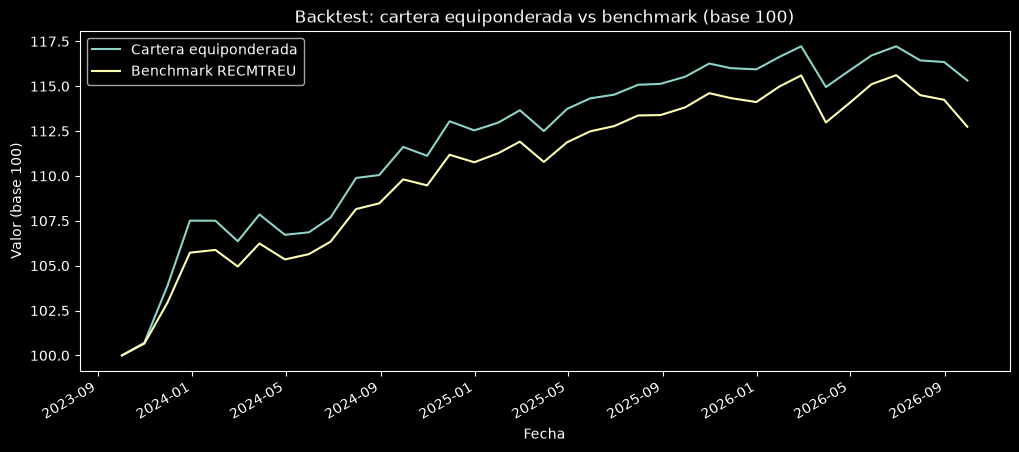

Rentabilidad acumulada (%):
Cartera equiponderada    15.32
Benchmark RECMTREU       12.74
Name: 2026-09-30 00:00:00, dtype: float64


In [58]:
# Evolución acumulada de 100 € invertidos en la cartera y en el benchmark
evolucion = pd.DataFrame({
    'Cartera equiponderada': (1 + backtest['Rent cartera']).cumprod() * 100,
    'Benchmark RECMTREU': (1 + backtest['Rent benchmark']).cumprod() * 100,
})

# Añadimos el punto de partida (100) en la primera fecha de rebalanceo
evolucion.loc[fechas_reb[0]] = 100
evolucion = evolucion.sort_index()

evolucion.plot(figsize=(12, 5))
plt.title('Backtest: cartera equiponderada vs benchmark (base 100)')
plt.ylabel('Valor (base 100)')
plt.show()

print('Rentabilidad acumulada (%):')
print((evolucion.iloc[-1] / 100 - 1).mul(100).round(2))

In [59]:
# Estadísticas anualizadas de la cartera y del benchmark (datos mensuales -> x12)
def estadisticas(rent):
    """Rentabilidad anualizada, volatilidad anualizada, ratio rent/vol y máximo drawdown."""
    valor = (1 + rent).cumprod()
    n_anios = len(rent) / 12
    return pd.Series({
        'Rent. acumulada (%)': (valor.iloc[-1] - 1) * 100,
        'Rent. anualizada (%)': (valor.iloc[-1] ** (1 / n_anios) - 1) * 100,
        'Volatilidad anual (%)': rent.std() * np.sqrt(12) * 100,
        'Rent / Vol': (valor.iloc[-1] ** (1 / n_anios) - 1) / (rent.std() * np.sqrt(12)),
        'Máx. drawdown (%)': ((valor / valor.cummax()) - 1).min() * 100,
    })

stats = pd.DataFrame({
    'Cartera': estadisticas(backtest['Rent cartera']),
    'Benchmark': estadisticas(backtest['Rent benchmark']),
})
print(stats.round(2), '\n')

# Comparación activa: tracking error y ratio de información
tracking_error = backtest['Dif'].std() * np.sqrt(12)
ratio_info = backtest['Dif'].mean() * 12 / tracking_error
print(f'Tracking error anual: {tracking_error * 100:.2f}%')
print(f'Ratio de información: {ratio_info:.2f}')
print(f"Meses batiendo al benchmark: {(backtest['Dif'] > 0).sum()} de {len(backtest)}")

                       Cartera  Benchmark
Rent. acumulada (%)      15.32      12.74
Rent. anualizada (%)      4.87       4.08
Volatilidad anual (%)     3.80       3.41
Rent / Vol                1.28       1.19
Máx. drawdown (%)        -1.93      -2.48 

Tracking error anual: 0.87%
Ratio de información: 0.89
Meses batiendo al benchmark: 18 de 36


**Resultados del backtest (02/10/2023 – 30/09/2026).**

| | Cartera equiponderada | Benchmark RECMTREU |
|---|---|---|
| Rentabilidad acumulada | **+15,32%** | +12,74% |
| Rentabilidad anualizada | **4,87%** | 4,08% |
| Volatilidad anual | 3,80% | 3,41% |
| Rentabilidad / volatilidad | **1,28** | 1,19 |
| Máximo drawdown | **−1,93%** | −2,48% |

- La cartera **bate al benchmark** en unos 2,6 puntos acumulados (≈ 0,8 puntos al año), con un **tracking error del 0,87%** y un **ratio de información de 0,89**.
- Asume algo más de volatilidad, pero obtiene **mejor rentabilidad por unidad de riesgo** y un **menor drawdown máximo**.
- Sin embargo, el resultado debe leerse con cautela: **solo bate al benchmark en 18 de los 36 meses**. Gran parte del diferencial se genera en noviembre y diciembre de 2023 (+0,88% y +0,79% de diferencia), durante el rally de final de año. Después, las dos líneas evolucionan casi en paralelo.
- Junto con el sesgo de supervivencia, esto sugiere que la ventaja de la cartera se debe más a su **mayor sensibilidad a tipos y spreads** en un periodo favorable que a una superioridad sistemática de la estrategia.

In [60]:
# Tabla para results con las columnas requeridas
backtest_csv = backtest[['Rent cartera', 'Rent benchmark', 'Dif']].copy()
backtest_csv.index = backtest_csv.index.strftime('%Y-%m')   # mes de cada periodo
backtest_csv.index.name = 'Fecha Mes'

backtest_csv.to_csv(RUTA_RESULTS + 'backtest_equal_weight.csv', sep=';')
print('Guardado:', os.path.abspath(RUTA_RESULTS + 'backtest_equal_weight.csv'))
backtest_csv.head()

Guardado: c:\Users\guada\Taller_renta_fija_Pablo_Modet\results\backtest_equal_weight.csv


,Rent cartera,Rent benchmark,Dif
Fecha Mes,,,
2023-10,0.007075,0.006548,0.000527
2023-11,0.031525,0.022696,0.008829
2023-12,0.034905,0.027038,0.007867
2024-01,-0.000028,0.001467,-0.001495
2024-02,-0.010646,-0.008735,-0.001910


**¿Qué sería lo más correcto en lugar de utilizar los precios MID?**
Utilizar los precios a los que realmente se puede operar: el **precio ASK al comprar** y el **precio BID al vender** (o, mejor aún, los precios efectivamente ejecutados). El MID es un punto intermedio al que no se puede negociar, así que usarlo ignora el coste de la horquilla. Con una horquilla mediana de ~0,20 puntos y un rebalanceo mensual de más de 2.000 bonos, este coste sería relevante y **reduciría la rentabilidad de la cartera**. El mismo argumento aplica a las comisiones de intermediación, que tampoco hemos incluido.

**¿Se te ocurre algún otro benchmark que se podría utilizar?**
- **Índices amplios de crédito corporativo en euros**, como el ICE BofA Euro Corporate Index, el Bloomberg Euro Aggregate Corporate o el iBoxx € Corporates.
- Un índice con una **duración similar** a la de la cartera (p. ej. un tramo 1-5 años), para que la comparación no dependa de la diferente sensibilidad a los tipos.
- Un índice **equiponderado** del mismo universo, que aislaría el efecto de la selección de bonos del de la ponderación.
- Un **ETF de crédito corporativo en euros**: es una alternativa de inversión real y ya incluye costes.
- El **€STR capitalizado**, para medir el exceso de rentabilidad sobre el activo libre de riesgo.

**Limitaciones del backtest:** sesgo de supervivencia, ausencia de costes de transacción y una equiponderación que da el mismo peso a una emisión de 250M que a una de 3.000M, sin tener en cuenta su liquidez.

**Mejoras propuestas:**
- Incluir los costes de transacción (precios BID/ASK) en cada rebalanceo.
- Ponderar por nominal vivo, como hacen los índices, y comparar con la versión equiponderada.
- Repetir el backtest con un universo libre de sesgo de supervivencia (incluyendo los bonos vencidos o impagados en el periodo).
- Comparar la duración y el spread medios de la cartera con los del benchmark, para explicar el diferencial de rentabilidad.

### <font color=#336699>6. Cartera mandato</font>

Tienes el mandato de **construir una cartera** de como máximo **20** bonos corporativos con ese universo y una serie de restricciones y, claro, maximizando la rentabilidad total de la cartera:
- La duración de la cartera no debe superar los 3 años
- La exposición a emisiones HY no puede superar el 10% de la cartera
- No puedes invertir en deuda subordinada
- No se puede invertir en emisiones de tamaño igual o inferior a 500 millones
- No se puede invertir más de un 10% del capital en una misma emisión
- No puede haber más de un 15% de concentración en un mismo emisor
(¡OJO! No estamos teniendo en cuenta en este ejercicio si hubiera un mínimo de inversión, lo cuál sería un dato relevante tener en cuenta en un caso real)

1. Constrúyela a fecha 1/10/2026

2. Teniendo en cuenta la naturaleza que nos están pidiendo para la cartera, ¿añadirías alguna otra restricción?

3. ¿Cómo medirías el riesgo de crédito de la cartera?

4. ¿Cómo medirías el riesgo de liquidez de la cartera? ¿Se te ocurre alguna otra información que se podría utilizar aunque no se te haya dado?

5. Describe cómo habría que hacer el backtest de esta cartera (no hace falta que lo implementes en este caso).


**Guarda en "results" una tabla llamada "cartera_optima.csv" que contenga:**

- ISIN
- Peso
- Yield
- Duration
- Rating
- Issuer
- Outstanding Amount
- Seniority
- Industry Sector

Y UNA FILA CON ISIN "CARTERA" CON LA DURACIÓN Y LA YIELD DE LA CARTERA RESULTANTE

In [61]:
# Bonos elegibles para el mandato
# - Excluimos la deuda subordinada (incluida la Sr Non Preferred, por prudencia)
# - Solo emisiones de más de 500 millones (excluidos los "igual o inferior")
# - Excluimos los bonos con yield poco fiable (marcados en la sección 3): plazos de pocos días
#   o precios incoherentes darían yields artificialmente altas que el optimizador elegiría
prelacion_excluida = ['Subordinated', 'Jr Subordinated', 'Sr Non Preferred']

filtros = pd.DataFrame({
    'No subordinada': ~universo['Seniority'].isin(prelacion_excluida),
    'Tamaño > 500M': universo['Outstanding Amount'] > 500e6,
    'Yield fiable': ~universo['ZSpread_PocoFiable'],
})
elegible = filtros.all(axis=1)

print('Bonos que cumplen cada filtro:')
print(filtros.sum().to_string())
print(f'\nBonos elegibles (cumplen todos): {elegible.sum()}')

# Tabla de candidatos con los datos que necesita el optimizador
candidatos = universo.loc[elegible, ['Description', 'Issuer', 'Rating', 'Categoria', 'Industry Sector',
                                     'Seniority', 'Outstanding Amount', 'Plazo_efectivo']]
candidatos = candidatos.join(sensibilidad[['Yield', 'Dur']])
candidatos['HY'] = candidatos['Categoria'] != 'IG'     # HY o sin rating

print(f"Candidatos HY o sin rating: {candidatos['HY'].sum()} | Emisores distintos: {candidatos['Issuer'].nunique()}")

Bonos que cumplen cada filtro:
No subordinada    1812
Tamaño > 500M     1398
Yield fiable      1917

Bonos elegibles (cumplen todos): 1031
Candidatos HY o sin rating: 120 | Emisores distintos: 356


**Universo elegible.** Aplicamos las restricciones del mandato que filtran bonos individuales:
- **No subordinada:** excluimos Subordinated y Jr Subordinated, y también la **Sr Non Preferred**. Aunque es deuda senior, en una resolución bancaria absorbe pérdidas antes que la senior preferente, así que la tratamos como subordinada por prudencia.
- **Tamaño > 500M:** hay que excluir las emisiones de tamaño "igual o inferior" a 500 millones, por lo que quedan fuera también las de exactamente 500M.
- **Yield fiable** (restricción añadida por nosotros): excluimos los bonos marcados en la sección 3 con z-spread poco fiable (plazos de pocos días, calls a punto de vencer o spreads fuera de rango). Sus yields anualizadas son artificialmente altas (p. ej. ARRFP, 39%) y el optimizador los elegiría aunque no representen una rentabilidad real.

Quedan **1.031 bonos elegibles** de 356 emisores. De ellos, 120 son HY o sin rating, que en el mandato **cuentan como HY**.

In [62]:
# Límite por emisor a nivel de GRUPO económico: distintas entidades emisoras de un mismo grupo
# comparten el riesgo de crédito (si el grupo quiebra, caen todos sus bonos).
# PSA Tresorerie GIE y Banque Stellantis France son filiales de Stellantis.
grupos = {
    'STELLANTIS NV': 'STELLANTIS',
    'PSA TRESORERIE GIE': 'STELLANTIS',
    'BANQUE STELLANTIS FRANCE': 'STELLANTIS',
}
candidatos['Grupo'] = candidatos['Issuer'].replace(grupos)
print(candidatos.loc[candidatos['Grupo'] == 'STELLANTIS', ['Description', 'Issuer', 'Yield']])

                    Description              Issuer     Yield
ISIN                                                         
FR0010014845  PEUGOT 6 09/19/33  PSA TRESORERIE GIE  0.056312
FR0013447166  STLA 1 ⅛ 09/18/29       STELLANTIS NV  0.049846
XS2199351375  STLA 4 ½ 07/07/28       STELLANTIS NV  0.038024
XS2356040357  STLA 0 ¾ 01/18/29       STELLANTIS NV  0.048331
XS2356041165  STLA 1 ¼ 06/20/33       STELLANTIS NV  0.060477
XS2464732770  STLA 2 ¾ 04/01/32       STELLANTIS NV  0.057085
XS2597110027  STLA 4 ⅜ 03/14/30       STELLANTIS NV  0.048826
XS2634690114  STLA 4 ¼ 06/16/31       STELLANTIS NV  0.054149


In [63]:
# Comparación: ¿qué pasaría si aplicáramos el límite del 15% por emisor legal ('Issuer') en lugar de por grupo?
pesos_por_issuer = fa.optimizar_mandato(candidatos)          # límite por 'Issuer' (valor por defecto)
expo_grupo = (candidatos.loc[pesos_por_issuer.index]
              .assign(Peso=pesos_por_issuer)
              .groupby('Grupo')['Peso'].sum())
yield_por_issuer = (pesos_por_issuer * candidatos.loc[pesos_por_issuer.index, 'Yield']).sum()

print(f'Exposición máxima por grupo económico: {expo_grupo.max():.1%} ({expo_grupo.idxmax()})')
print(f'Yield de esa cartera: {yield_por_issuer:.3%}')

Exposición máxima por grupo económico: 25.0% (STELLANTIS)
Yield de esa cartera: 5.076%


**Límite por grupo emisor.** El campo `Issuer` identifica la entidad legal que emite el bono, no el grupo económico. Si aplicamos el límite del 15% por `Issuer`, el optimizador elige bonos de **PSA Tresorerie GIE** (filial de Stellantis) junto con dos bonos de **Stellantis NV**: cada emisor cumple formalmente el límite, pero la exposición real al grupo Stellantis es del **25%**. Como todas las entidades de un grupo comparten el riesgo de crédito (si el grupo quiebra, caen todos sus bonos), aplicamos el límite por **grupo económico**. Cumplirlo correctamente reduce la yield de la cartera de 5,08% a 5,02% (unos 5 pb). Hemos comprobado que el resto de emisores seleccionados no pertenecen a un mismo grupo.

*Limitación:* solo hemos revisado los grupos de los bonos seleccionados. Lo correcto sería mapear todos los emisores del universo a su matriz última (p. ej. el campo *Ultimate Parent* de Bloomberg), un dato que no se nos ha dado.

In [64]:
# Construimos la cartera óptima a 01/10/2026
# (límite por emisor aplicado a nivel de grupo económico: columna 'Grupo')
pesos = fa.optimizar_mandato(candidatos, col_emisor='Grupo')
cartera = candidatos.loc[pesos.index].assign(Peso=pesos).sort_values('Peso', ascending=False)

# Comprobación de todas las restricciones del mandato
yield_cartera = (cartera['Peso'] * cartera['Yield']).sum()
dur_cartera = (cartera['Peso'] * cartera['Dur']).sum()

print(f'Número de bonos:              {len(cartera)} (máx. 20)')
print(f"Suma de pesos:                {cartera['Peso'].sum():.4f}")
print(f'Duración de la cartera:       {dur_cartera:.3f} años (máx. 3)')
print(f"Exposición HY / sin rating:   {cartera.loc[cartera['HY'], 'Peso'].sum():.1%} (máx. 10%)")
print(f"Peso máximo por emisión:      {cartera['Peso'].max():.1%} (máx. 10%)")
print(f"Peso máximo por grupo emisor: {cartera.groupby('Grupo')['Peso'].sum().max():.1%} (máx. 15%)")
print(f'Yield de la cartera:          {yield_cartera:.3%}')

cartera[['Description', 'Issuer', 'Grupo', 'Rating', 'Industry Sector', 'Plazo_efectivo', 'Yield', 'Dur', 'Peso']].round(4)

Número de bonos:              12 (máx. 20)
Suma de pesos:                1.0000
Duración de la cartera:       3.000 años (máx. 3)
Exposición HY / sin rating:   10.0% (máx. 10%)
Peso máximo por emisión:      10.0% (máx. 10%)
Peso máximo por grupo emisor: 15.0% (máx. 15%)
Yield de la cartera:          5.023%


,Description,Issuer,Grupo,Rating,Industry Sector,Plazo_efectivo,Yield,Dur,Peso
ISIN,,,,,,,,,
XS2384716721,DXC 0.95 09/15/31,DXC CAPITAL FUNDING LTD,DXC CAPITAL FUNDING LTD,BBB-,Technology,4.7068,0.0554,4.6121,0.1000
XS2356041165,STLA 1 ¼ 06/20/33,STELLANTIS NV,STELLANTIS,BBB,"Consumer, Cyclical",6.4712,0.0605,6.1876,0.1000
XS2407010656,JDEPNA 0 ⅝ 02/09/28,JDE PEET'S NV,JDE PEET'S NV,BBB-,"Consumer, Non-cyclical",1.1068,0.0458,1.1021,0.1000
XS2397252011,HEIBOS 1 ⅝ 10/13/31,HEIMSTADEN BOSTAD TRESRY,HEIMSTADEN BOSTAD TRESRY,BBB-,Financial,4.7836,0.0507,4.5432,0.1000
XS2489775580,SESGFP 3 ½ 01/14/29,SES SA,SES SA,BBB-,Communications,2.0384,0.0491,1.9531,0.1000
XS2430287362,PRXNA 2.085 01/19/30,PROSUS NV,PROSUS NV,BBB,Communications,3.0521,0.0474,2.9405,0.1000
XS2459163619,LXSGR 1 ¾ 03/22/28,LANXESS AG,LANXESS AG,NR,Basic Materials,1.2247,0.0503,1.2114,0.1000
XS2227905903,AMT 0 ½ 01/15/28,AMERICAN TOWER CORP,AMERICAN TOWER CORP,BBB,Financial,1.0384,0.0442,1.0345,0.0928
XS2390546849,CTPNV 1 ½ 09/27/31,CTP NV,CTP NV,BBB-,Financial,4.7397,0.0486,4.5966,0.0572


**1. Construcción de la cartera (01/10/2026).** Maximizamos la **yield media ponderada** de la cartera con un problema de **programación lineal entera mixta (MILP)**. Los pesos son variables continuas y, para limitar el número de bonos a 20, añadimos una variable binaria por bono (entra o no entra en cartera), enlazada con su peso: $w_i \le 10\% \cdot z_i$. `scipy.optimize.milp` encuentra la solución óptima exacta.

**Resultado:** 12 bonos con una **yield del 5,02%** y una **duración de 3,00 años**, que cumplen todas las restricciones del mandato.
- Las restricciones de duración (3 años), HY (10%), peso por emisión (10%) y peso por grupo emisor (15%) quedan **exactamente en su límite**: son las que limitan la rentabilidad, y si se relajaran la yield aumentaría.
- El optimizador usa solo 12 bonos, no 20: con un máximo del 10% por emisión bastarían 10, y solo reparte en más bonos donde lo obligan los límites por grupo y de duración.
- La cartera combina bonos cortos (1–2 años) con otros más largos (5–6 años) para que la duración media quede justo en 3 años, aprovechando las yields más altas de los plazos largos.

In [65]:
# Tabla para results: un bono por fila + una fila "CARTERA" con la duración y la yield de la cartera
cols_csv = ['Peso', 'Yield', 'Dur', 'Rating', 'Issuer', 'Outstanding Amount', 'Seniority', 'Industry Sector']
cartera_csv = cartera[cols_csv].rename(columns={'Dur': 'Duration'})

fila_cartera = pd.DataFrame(
    {'Peso': [cartera['Peso'].sum()], 'Yield': [yield_cartera], 'Duration': [dur_cartera]},
    index=['CARTERA']
)
cartera_csv = pd.concat([cartera_csv, fila_cartera])
cartera_csv.index.name = 'ISIN'

cartera_csv.to_csv(RUTA_RESULTS + 'cartera_optima.csv', sep=';')
print('Guardado:', os.path.abspath(RUTA_RESULTS + 'cartera_optima.csv'))
cartera_csv.round(4)

Guardado: c:\Users\guada\Taller_renta_fija_Pablo_Modet\results\cartera_optima.csv


,Peso,Yield,Duration,Rating,Issuer,Outstanding Amount,Seniority,Industry Sector
ISIN,,,,,,,,
XS2384716721,0.1000,0.0554,4.6121,BBB-,DXC CAPITAL FUNDING LTD,6.000000e+08,Sr Unsecured,Technology
XS2356041165,0.1000,0.0605,6.1876,BBB,STELLANTIS NV,1.250000e+09,Sr Unsecured,"Consumer, Cyclical"
XS2407010656,0.1000,0.0458,1.1021,BBB-,JDE PEET'S NV,6.000000e+08,Sr Unsecured,"Consumer, Non-cyclical"
XS2397252011,0.1000,0.0507,4.5432,BBB-,HEIMSTADEN BOSTAD TRESRY,7.500000e+08,Sr Unsecured,Financial
XS2489775580,0.1000,0.0491,1.9531,BBB-,SES SA,7.500000e+08,Sr Unsecured,Communications
XS2430287362,0.1000,0.0474,2.9405,BBB,PROSUS NV,6.000000e+08,Sr Unsecured,Communications
XS2459163619,0.1000,0.0503,1.2114,NR,LANXESS AG,6.000000e+08,Sr Unsecured,Basic Materials
XS2227905903,0.0928,0.0442,1.0345,BBB,AMERICAN TOWER CORP,7.500000e+08,Sr Unsecured,Financial
XS2390546849,0.0572,0.0486,4.5966,BBB-,CTP NV,5.495000e+08,Sr Unsecured,Financial


Guardamos `cartera_optima.csv` con los 12 bonos de la cartera y una fila **CARTERA** con su yield (5,02%) y su duración (3,00 años), como pide el enunciado. Los pesos y la yield están en tanto por uno (0,10 = 10%), y la duración es la de **Macaulay**, en años: al ser mayor o igual que la duración modificada, cumplir el límite de 3 años con ella garantiza cumplirlo con cualquiera de las dos. 
*Interpretación:* entendemos la "duración de la cartera" como la media de las duraciones de los bonos ponderada por su peso, que es la práctica habitual. Usamos la duración de Macaulay, que es mayor o igual que la modificada: así el límite de 3 años se cumple con cualquiera de las dos lecturas. No lo interpretamos como un límite por bono sino la duración (media) *de la cartera*.

##### <font color=#CC6600>Riesgo de crédito</font>

In [66]:
# Riesgo de crédito de la cartera, comparado con el universo
escala_num = {r: i + 1 for i, r in enumerate(escala[:-1])}     # AAA = 1, AA+ = 2, ..., B- = 16 (sin 'NR')
riesgo = cartera[['Peso', 'Rating', 'Industry Sector', 'Dur']].join(universo[['PD 1YR', 'Spread_pb']])
riesgo['RatingNum'] = riesgo['Rating'].map(escala_num)        # 'NR' queda como NaN

# 1) Distribución por rating (peso en cartera)
print('Peso por rating:')
print(riesgo.groupby('Rating')['Peso'].sum().map('{:.1%}'.format).to_string())

# 2) Rating medio ponderado (solo bonos con rating)
con_rating = riesgo.dropna(subset=['RatingNum'])
rating_medio = (con_rating['Peso'] * con_rating['RatingNum']).sum() / con_rating['Peso'].sum()
print(f'\nRating medio ponderado: {rating_medio:.2f} (BBB = {escala_num["BBB"]}, BBB- = {escala_num["BBB-"]})')

# 3) PD y z-spread medios ponderados, frente a la mediana del universo
pd_cartera = (riesgo['Peso'] * riesgo['PD 1YR']).sum()
spread_cartera = (riesgo['Peso'] * riesgo['Spread_pb']).sum()
print(f"PD 1 año ponderada: {pd_cartera:.5f} | mediana del universo: {universo['PD 1YR'].median():.5f}")
print(f"z-spread ponderado: {spread_cartera:.1f} pb | mediana del universo: {universo['Spread_pb'].median():.1f} pb")

# 4) Duration Times Spread (DTS): sensibilidad de la cartera a movimientos relativos del spread
dts = (riesgo['Peso'] * riesgo['Spread_pb'] * riesgo['Dur']).sum()
print(f'DTS de la cartera: {dts:.0f}')

# 5) Concentración por sector
print('\nPeso por sector:')
print(riesgo.groupby('Industry Sector')['Peso'].sum().map('{:.1%}'.format).to_string())

Peso por rating:
Rating
BBB     39.3%
BBB-    50.7%
NR      10.0%

Rating medio ponderado: 9.56 (BBB = 9, BBB- = 10)
PD 1 año ponderada: 0.00721 | mediana del universo: 0.00013
z-spread ponderado: 184.8 pb | mediana del universo: 90.0 pb
DTS de la cartera: 604

Peso por sector:
Industry Sector
Basic Materials           10.0%
Communications            25.0%
Consumer, Cyclical        15.0%
Consumer, Non-cyclical    10.0%
Financial                 30.0%
Technology                10.0%


Pais
Países Bajos    45.7%
EE. UU.         19.3%
Suecia          15.0%
Alemania        10.0%
Luxemburgo      10.0%


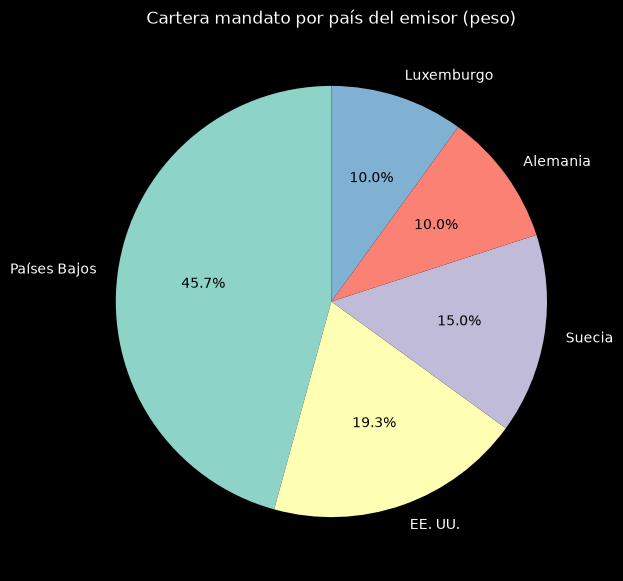

In [67]:
# País de la sede de cada emisor de la cartera (no viene en los datos: lo asignamos a mano)
pais_emisor = {
    'DXC CAPITAL FUNDING LTD':  'EE. UU.',        # DXC Technology
    'STELLANTIS NV':            'Países Bajos',   # sede legal; grupo franco-italiano
    "JDE PEET'S NV":            'Países Bajos',
    'HEIMSTADEN BOSTAD TRESRY': 'Suecia',         # filial financiera de Heimstaden Bostad AB
    'SES SA':                   'Luxemburgo',
    'PROSUS NV':                'Países Bajos',   # filial de Naspers (Sudáfrica)
    'LANXESS AG':               'Alemania',
    'AMERICAN TOWER CORP':      'EE. UU.',
    'CTP NV':                   'Países Bajos',   # sede en Ámsterdam; activos en Europa Central
}
expo_pais = (cartera.assign(Pais=cartera['Issuer'].map(pais_emisor))
                    .groupby('Pais')['Peso'].sum()
                    .sort_values(ascending=False))
print(expo_pais.map('{:.1%}'.format).to_string())

fig, ax = plt.subplots(figsize=(7, 7))
_, _, porcentajes = ax.pie(expo_pais, labels=expo_pais.index, autopct='%1.1f%%', startangle=90)
for texto in porcentajes:
    texto.set_color('black')       # porcentajes en negro: se leen bien sobre colores claros
ax.set_title('Cartera mandato por país del emisor (peso)')
plt.show()

**Concentración geográfica.** Asignando a mano el país de la sede de los 9 emisores de la cartera, el 45,7% está en **Países Bajos**, el 19,3% en EE. UU., el 15% en Suecia y el 10% en Alemania y en Luxemburgo. Pero la sede legal no refleja el riesgo económico: muchos grupos sitúan sus sociedades holding o financieras en Países Bajos por motivos legales y fiscales, mientras su negocio está en otros países (Stellantis en Francia e Italia, Prosus en China a través de Tencent y en Sudáfrica, CTP en la República Checa y Europa Central). Para medir bien el riesgo país haría falta el **país de riesgo** de cada emisor (p. ej. el campo *Country of Risk* de Bloomberg), que no se nos ha dado. Por eso proponemos añadir al mandato un **límite por país de riesgo** (pregunta 2).

**2. ¿Añadirías alguna otra restricción?** Sí. El análisis de riesgo de crédito (celda anterior) muestra que, para maximizar la yield, el optimizador elige los bonos con **más riesgo de crédito que permiten las reglas**: toda la cartera es BBB o BBB-, la parte más baja del *Investment Grade*, más el máximo permitido en bonos sin rating. Para una cartera de perfil conservador (*Investment Grade* y duración corta) añadiríamos:
- **Rating medio mínimo** (p. ej. A-) o **peso máximo en BBB-**: el 50,7% de la cartera está a un solo escalón del *High Yield*. Una rebaja de rating convertiría esos bonos en HY y la cartera **incumpliría el límite del 10%** (riesgo de *fallen angel* cuando un bono va de IG a HY), obligando a vender en mal momento.
- **Límite por sector** (p. ej. 25%), para evitar concentraciones como el 30% en financieros.
- **Spread o PD máximos por bono**, para no comprar bonos que el mercado ya considera muy arriesgados.
- **Número mínimo de bonos o de emisores**, para diversificar más que con 12 bonos.
- **Límite por grupo económico** (ya aplicado) y **por país**.
- **Liquidez mínima** (horquilla máxima o tamaño mínimo mayor) y, si el mandato busca una duración objetivo, también una **duración mínima**.
- **Excluir bonos con yield poco fiable** (ya aplicado): plazos de pocos días o precios incoherentes.

**3. ¿Cómo medirías el riesgo de crédito de la cartera?** Con varios indicadores complementarios:
- **Distribución por rating y rating medio:** 39,3% BBB, 50,7% BBB- y 10% sin rating; el rating medio ponderado (9,56 en una escala AAA = 1) está entre BBB y BBB-.
- **Probabilidad de impago (PD) a 1 año** ponderada: 0,0072, muy por encima de la mediana del universo (0,00013).
- **z-spread ponderado:** 185 pb, el **doble** que la mediana del universo (90 pb). Es la prima que el mercado exige por el riesgo de la cartera.
- **DTS (*Duration Times Spread*):** 604. Mide la sensibilidad de la cartera a los movimientos del spread, que tienden a ser proporcionales a su nivel: un bono con más spread y más duración tiene más riesgo de crédito.
- **Concentración:** máximo 15% por grupo emisor y 30% en el sector financiero.
- Otras medidas posibles: **pérdida esperada** (PD × LGD × exposición), **VaR o CVaR de crédito** con un modelo de impago y de migración de ratings, o **escenarios de estrés** de spreads (sección 9).

##### <font color=#CC6600>Riesgo de liquidez</font>

In [68]:
# Riesgo de liquidez de la cartera, comparado con el universo
liq = cartera[['Peso', 'Dur']].join(universo[['Price', 'Horquilla', 'Outstanding Amount']])

# 1) Horquilla bid-ask ponderada, en puntos de precio
horq_cartera = (liq['Peso'] * liq['Horquilla']).sum()
print(f"Horquilla ponderada: {horq_cartera:.3f} puntos | mediana del universo: {universo['Horquilla'].median():.3f}")

# 2) Horquilla en pb de rentabilidad (horquilla / (precio · duración)): coste de entrar y salir
#    comparable entre bonos de distinto plazo (la "mejora" propuesta en la sección 1)
liq['Horquilla_pb'] = liq['Horquilla'] / (liq['Price'] * liq['Dur']) * 1e4
horq_pb_universo = (universo['Horquilla'] / (universo['Price'] * sensibilidad['Dur']) * 1e4).median()
print(f"Horquilla en pb de rentabilidad: {(liq['Peso'] * liq['Horquilla_pb']).sum():.1f} pb | "
      f"mediana del universo: {horq_pb_universo:.1f} pb")

# 3) Tamaño de las emisiones
nominal_medio = (liq['Peso'] * liq['Outstanding Amount']).sum() / 1e6
print(f"Nominal vivo medio ponderado: {nominal_medio:.0f} M | mediana del universo: "
      f"{universo['Outstanding Amount'].median() / 1e6:.0f} M | mínimo en cartera: {liq['Outstanding Amount'].min() / 1e6:.0f} M")

# 4) Tamaño de nuestra posición frente a la emisión, para una cartera de 100 millones
liq['% de la emision'] = 100e6 * liq['Peso'] / liq['Outstanding Amount'] * 100
print(f"Posición máxima sobre el tamaño de la emisión (cartera de 100 M): {liq['% de la emision'].max():.2f}%")

Horquilla ponderada: 0.259 puntos | mediana del universo: 0.202
Horquilla en pb de rentabilidad: 11.5 pb | mediana del universo: 8.6 pb
Nominal vivo medio ponderado: 746 M | mediana del universo: 700 M | mínimo en cartera: 550 M
Posición máxima sobre el tamaño de la emisión (cartera de 100 M): 1.67%


**4. ¿Cómo medirías el riesgo de liquidez de la cartera?** Con indicadores del coste y la facilidad de vender los bonos:
- **Horquilla bid-ask ponderada:** 0,259 puntos, frente a una mediana del universo de 0,202. Es el coste de comprar y vender de inmediato.
- **Horquilla en pb de rentabilidad** (horquilla / (precio × duración)): 11,5 pb, frente a 8,6 pb en el universo. Mide cuánta rentabilidad se pierde al entrar y salir, y hace comparables bonos de distinto plazo (la mejora que propusimos en la sección 1).
- **Tamaño de las emisiones:** nominal vivo medio ponderado de 746M (mínimo 550M), algo por encima de la mediana del universo (700M). Las emisiones grandes suelen negociarse más y tener más *dealers* cotizándolas.
- **Peso de nuestra posición en cada emisión:** con una cartera de 100M, como máximo el 1,67% de una emisión, así que podríamos vender sin mover mucho el precio.

**Conclusión:** la cartera es algo **menos líquida** que el universo (horquillas ~30% más anchas, tanto en puntos como en pb de rentabilidad), en línea con su menor calidad crediticia: los bonos con más riesgo suelen cotizar con horquillas más amplias. En cambio, el tamaño de las posiciones no es un problema.

**¿Se te ocurre alguna otra información que se podría utilizar?**
- **Volúmenes y número de operaciones** de cada bono (p. ej. datos post-negociación de MiFID II en Europa o TRACE en EE. UU.).
- **Número de *dealers*** que cotizan cada bono y la **profundidad** de sus cotizaciones (qué importe aceptan a ese precio).
- **Puntuaciones de liquidez** de proveedores de datos (p. ej. Bloomberg LQA), que estiman el coste y el tiempo de liquidar una posición.
- **Días estimados para liquidar** la posición sin mover el precio, comparando su tamaño con el volumen diario negociado.
- **Elegibilidad como colateral** en repo o en las operaciones del BCE, que aumenta la demanda y la liquidez del bono.
- **Evolución de la horquilla en periodos de estrés** (p. ej. marzo de 2020), para ver cómo se comporta la liquidez cuando más se necesita.

##### <font color=#CC6600>Backtest</font>

**5. ¿Cómo habría que hacer el backtest de esta cartera?** No lo implementamos, pero el procedimiento sería:

1. **Fechas de rebalanceo:** p. ej. mensuales, como en la sección 5 (último día hábil de cada mes).
2. **En cada fecha, reconstruir la cartera solo con la información disponible en ese momento** (*point-in-time*), para evitar el *look-ahead bias*:
   - universo vivo en esa fecha (bonos ya emitidos y sin vencer), con los ratings, el nominal vivo y la prelación de ese momento;
   - precios de mercado de esa fecha y la **curva €STR de esa fecha**: solo tenemos la del 01/10/2026, así que harían falta curvas históricas;
   - recalcular yields, duraciones y z-spreads, aplicar los mismos filtros y volver a ejecutar el optimizador con las restricciones del mandato.
3. **Mantener la cartera hasta el siguiente rebalanceo** y medir su **rentabilidad total** (precio + cupón corrido + cupones cobrados), como en la sección 5, incluyendo los bonos que se amortizan o se *callean* durante el periodo (el efectivo se reinvierte en el siguiente rebalanceo).
4. **Incluir costes de transacción:** comprar al ASK y vender al BID. Como el optimizador puede cambiar mucho la cartera de un mes a otro, convendría limitar la **rotación** (*turnover*) o rebalancear solo cuando la mejora de yield compense los costes.
5. **Vigilar el cumplimiento del mandato entre rebalanceos:** p. ej. un bono que pierde el grado de inversión (*fallen angel*) puede hacer que la cartera supere el límite de HY y obligue a vender.
6. **Comparar con un benchmark adecuado:** un índice de crédito *Investment Grade* en euros de **duración similar** (p. ej. un tramo 1–5 años), con las mismas métricas que en la sección 5: rentabilidad, volatilidad, drawdown, tracking error y ratio de información.
7. **Usar un universo sin sesgo de supervivencia,** que incluya los bonos que vencieron, se amortizaron o impagaron en el periodo, ya que nuestro universo solo contiene bonos vivos en 2026.

### <font color=#336699>7. Cobertura tipos de interés</font>

**Cubre la exposición de la cartera a los tipos de interés.**

Utiliza alguno de los siguientes instrumentos para cubrir la duración (sensibilidad de tipos de interés) de la cartera que has construido según el mandato. Asume una inversión en la cartera de 10 millones:

- Futuros sobre el *Schatz* (ticker: DU1) - Duración a 01/10/2026: 1.92
- Futuros sobre el *BOBL* (ticker: OE1) - Duración a 01/10/2026: 5.44
- Futuros sobre el *BUND* (ticker: RX1) - Duración a 01/10/2026: 10

*Contract size* en todos los casos: 100,000 euros

Investiga sobre estos instrumentos antes de tomar la decisión. Razona tu elección del instrumento y el número de contratos que has decidido comprar/vender.

- ¿Qué pasaría si comprásemos/vendiésemos 100 futuros?
- ¿Se te ocurre algún otro instrumento con el que cubrir la sensibilidad a los tipos de interés de la cartera?


### <font color=#336699>8. Cobertura crédito</font>

**Cubre total o parcialmente el riesgo de crédito.**

Utiliza alguno de los siguientes instrumentos para cubrir el riesgo de crédito de la cartera que has construido según el mandato. Asume una inversión en la cartera de 10 millones€:

- ITRAXX Main (ticker: ITRX EUR CDSI GEN 5Y Corp)
- ITRAXX XOVER (ticker: ITRX XOVER CDSI GEN 5Y Corp)

Estos índices cotizan en forma de spread, en puntos básicos. La sensibilidad del valor del CDS es de 4,500€ al punto básico, asumiendo una inversión de 10 millones€.

Investiga sobre estos instrumentos antes de tomar la decisión. Razona tu elección del instrumento y el nominal que has decidido comprar/vender.

- ¿Tiene sentido plantear esta cobertura total?
- ¿Con qué otros instrumentos podrías cubrir el riesgo de crédito?
- ¿Qué riesgos permanecen después de la cobertura? Menciona al menos 3 y razónalos.


### <font color=#336699>9. Stress Test</font>

<style>.gray {background-color: #595959}

</style><div class="gray">

Teniendo en cuenta los siguientes escenarios de estrés:
- **Escenario A: shock de tipos**: movimiento de tipos a la alza de 100 pbs.
- **Escenario B: shock de crédito**: movimiento del spread de crédito (50 pbs para bonos *high yield* y 150 pbs para bonos *investment grade*).
- **Escenario C: crisis**: escenario conjunto de tipos y crédito.

Estima el impacto de cada escenario en la cartera a fecha 01/10/2026. Asume una inversión de 100 millones.

**Guarda en "results" una tabla llamada "stress_test.csv" que contenga el valor de la cartera y P&L en cada escenario incluyendo el escenario base de no estrés:**

- Escenario
- ValorCartera
- P&L

</div>